<a href="https://colab.research.google.com/github/rtnsr/Portfolio-XGB-BL-SkewNorm/blob/main/XGB_BL_SN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LOAD LIBRARY

In [ ]:
# Instal Package
!pip install yfinance xgboost optuna PyPortfolioOpt
!pip install rpy2 pandas

In [2]:
import pypfopt
pypfopt.__version__

'1.6.0'

In [3]:
# Manipulasi data
import random
import numpy as np
import pandas as pd
# Pengambilan data
import yfinance as yf
# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns
# Statistik
from scipy import stats
from scipy.stats import jarque_bera, norm, skewnorm
from scipy.optimize import brentq
from joblib import Parallel, delayed
from statsmodels.stats.multitest import multipletests
# Machine Learning
from xgboost import XGBRegressor
import optuna
from optuna.pruners import MedianPruner
# Evaluasi model
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
# Time Series Cross Validation
from sklearn.model_selection import TimeSeriesSplit
# Black-Litterman / Portfolio
import pypfopt
from pypfopt import (
    risk_models,
    black_litterman,
    expected_returns,
    BlackLittermanModel,
    EfficientFrontier,
    objective_functions,
    plotting
)
# Setup Tampilan & Logging
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
optuna.logging.set_verbosity(optuna.logging.WARNING)
import warnings
warnings.filterwarnings('ignore')
# Fungsi Pengunci Seed Global untuk Reproduksibilitas
SEED = 42
def set_global_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
set_global_seed(SEED)

# A. PREPARATION DATA

1. **Pre-Processing**: pembersihan missing-value dengan menghapus nilai NA,
2. **Statistik Deskriptif**: Menghitung statistik data empiris atau mengetahui karakteristik data sampel,
3. **Uji Normalitas Jarque-Bera**
4. **Parameter Skew-Normal**: estimasi parameter MLE
5. **Goodness-of-Fit**: evaluasi log-likelihood (nilai tertinggi), evaluasi AIC/BIC (nilai terkecil), dan validasi absolut dengan Kolmogorov-Smirnov.

## Pre-Processing

In [4]:
# Unduh Data: Periode Januari 2016 - Mei 2026
tickers = [
    'ACES.JK', 'ADRO.JK', 'AKRA.JK', 'ANTM.JK', 'ASII.JK',
    'BBCA.JK', 'BBNI.JK', 'BBRI.JK', 'BMRI.JK', 'BNGA.JK',
    'HMSP.JK', 'INDF.JK', 'ITMG.JK', 'JPFA.JK', 'PGAS.JK',
    'PTBA.JK', 'SIDO.JK', 'TLKM.JK', 'UNTR.JK', 'UNVR.JK'
]
saham = [
    "ACES", "ADRO", "AKRA", "ANTM", "ASII", "BBCA", "BBNI",
    "BBRI", "BMRI", "BNGA", "HMSP", "INDF", "ITMG", "JPFA",
    "PGAS", "PTBA", "SIDO", "TLKM", "UNTR", "UNVR"
]
start, end = '2016-01-01', '2026-06-01'
data = yf.download(
    tickers,
    start=start,
    end=end,
    auto_adjust=False,
    progress=False
)
# Adjusted Close Price
harga_saham_raw = (
    data["Adj Close"]
    .resample("W-FRI")
    .last()
)
harga_saham_raw.columns = saham
print("Ukuran data raw :", harga_saham_raw.shape)
display(harga_saham_raw.head())
display(harga_saham_raw.tail())

Ukuran data raw : (543, 20)


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2016-01-08,511.481720,112.890488,872.390930,224.631302,3445.185303,2039.035645,1643.259766,1243.424194,1335.624023,335.772400,2023.236084,3783.059814,1490.900879,411.240356,1391.840454,247.321106,152.918716,1841.577515,7556.884277,4893.676270
2016-01-15,542.376648,102.815079,778.001160,236.651718,3416.711914,2039.035645,1635.043335,1227.345459,1335.624023,332.997406,2092.778076,3816.390869,1406.632324,397.757050,1443.592041,256.513062,145.636871,1806.444092,7568.510254,4870.002930
2016-01-22,542.376648,117.928207,803.743713,231.392746,3359.767090,2039.035645,1643.259766,1208.587158,1350.024414,330.222443,1962.386963,3866.386963,1315.882324,448.319366,1356.431641,254.789612,145.636871,1865.000000,7591.763184,4815.892578
2016-01-29,549.242188,120.218063,840.927734,247.169556,3672.966064,2054.720215,1613.681030,1203.227539,1382.425049,335.772400,2249.247314,4133.033691,1247.171021,495.510803,1310.127686,255.651306,145.636871,1955.761353,8091.678711,4964.698242
2016-02-05,576.704285,146.551544,958.199890,256.936127,3786.855957,2105.696289,1733.639038,1318.458496,1490.426880,335.772400,2368.772461,4383.015625,1241.985229,508.994232,1321.022827,259.098358,148.549652,2049.450195,8045.174805,5492.280762


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2026-05-01,326.689667,2520.0,1477.162476,3485.013916,5571.921875,5808.839844,3720.0,2990.0,3971.258057,1670.0,692.551025,6466.304688,26650.0,2343.843262,1798.326416,2742.125244,500.0,2598.143311,28569.558594,1429.900879
2026-05-08,346.765564,2490.0,1448.805542,3382.513428,5706.319824,6131.553223,3860.0,3260.0,4188.365234,1690.0,701.785034,6681.848145,24300.0,2410.000000,1733.438354,2732.570801,478.0,2736.834229,26946.847656,1676.756836
2026-05-15,337.640167,2520.0,1405.341309,3261.376709,5632.848145,6057.080566,3870.0,3120.0,4136.128906,1675.0,683.317017,6538.152344,23950.0,2540.000000,1714.898926,2703.907471,444.0,2736.834229,26455.115234,1662.783813
2026-05-22,317.564270,2350.0,1303.924927,2879.329590,5289.979004,5858.488281,3780.0,3050.0,4057.345703,1645.0,683.317017,6442.354980,23175.0,2570.000000,1687.089722,2598.808594,408.0,2699.849854,23652.250000,1644.153198
2026-05-29,317.564270,2300.0,1192.849854,2702.283447,4898.128906,5659.895020,3700.0,2950.0,4017.954102,1615.0,695.000000,6633.949219,22100.0,2450.000000,1691.724609,2656.135254,384.0,2801.556641,22545.855469,1592.918945


**Cleaning 20 data saham**

In [5]:
# cek missing value
print("Missing Value Masing-masing Saham:")
display(harga_saham_raw.isna().sum().to_frame().T)
print("\nTotal Missing Value:")
print(harga_saham_raw.isna().sum().sum())

Missing Value Masing-masing Saham:


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
0,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4



Total Missing Value:
80


In [6]:
# Cleaning data saham
harga_saham_clean = harga_saham_raw.dropna().copy()
print("Ukuran harga :", harga_saham_clean.shape)
print("\nMissing Value Setelah Cleaning:")
print(harga_saham_clean.isna().sum().sum())
display(harga_saham_clean.head().round(2))
display(harga_saham_clean.tail().round(2))

Ukuran harga : (539, 20)

Missing Value Setelah Cleaning:
0


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2016-01-08,511.48,112.89,872.39,224.63,3445.19,2039.04,1643.26,1243.42,1335.62,335.77,2023.24,3783.06,1490.90,411.24,1391.84,247.32,152.92,1841.58,7556.88,4893.68
2016-01-15,542.38,102.82,778.00,236.65,3416.71,2039.04,1635.04,1227.35,1335.62,333.00,2092.78,3816.39,1406.63,397.76,1443.59,256.51,145.64,1806.44,7568.51,4870.00
2016-01-22,542.38,117.93,803.74,231.39,3359.77,2039.04,1643.26,1208.59,1350.02,330.22,1962.39,3866.39,1315.88,448.32,1356.43,254.79,145.64,1865.00,7591.76,4815.89
2016-01-29,549.24,120.22,840.93,247.17,3672.97,2054.72,1613.68,1203.23,1382.43,335.77,2249.25,4133.03,1247.17,495.51,1310.13,255.65,145.64,1955.76,8091.68,4964.70
2016-02-05,576.70,146.55,958.20,256.94,3786.86,2105.70,1733.64,1318.46,1490.43,335.77,2368.77,4383.02,1241.99,508.99,1321.02,259.10,148.55,2049.45,8045.17,5492.28


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2026-05-01,326.69,2520.0,1477.16,3485.01,5571.92,5808.84,3720.0,2990.0,3971.26,1670.0,692.55,6466.30,26650.0,2343.84,1798.33,2742.13,500.0,2598.14,28569.56,1429.90
2026-05-08,346.77,2490.0,1448.81,3382.51,5706.32,6131.55,3860.0,3260.0,4188.37,1690.0,701.79,6681.85,24300.0,2410.00,1733.44,2732.57,478.0,2736.83,26946.85,1676.76
2026-05-15,337.64,2520.0,1405.34,3261.38,5632.85,6057.08,3870.0,3120.0,4136.13,1675.0,683.32,6538.15,23950.0,2540.00,1714.90,2703.91,444.0,2736.83,26455.12,1662.78
2026-05-22,317.56,2350.0,1303.92,2879.33,5289.98,5858.49,3780.0,3050.0,4057.35,1645.0,683.32,6442.35,23175.0,2570.00,1687.09,2598.81,408.0,2699.85,23652.25,1644.15
2026-05-29,317.56,2300.0,1192.85,2702.28,4898.13,5659.90,3700.0,2950.0,4017.95,1615.0,695.00,6633.95,22100.0,2450.00,1691.72,2656.14,384.0,2801.56,22545.86,1592.92


**Return 20 saham**

In [7]:
# Log return: diff(log(harga))
return_saham = np.log(
    harga_saham_clean / harga_saham_clean.shift(1)
).dropna()
print("Ukuran return :", return_saham.shape)
print("Missing Value :", return_saham.isna().sum().sum())
display(return_saham.head().round(4))
display(return_saham.tail().round(4))

Ukuran return : (538, 20)
Missing Value : 0


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2016-01-15,0.0586,-0.0935,-0.1145,0.0521,-0.0083,0.0000,-0.0050,-0.0130,0.0000,-0.0083,0.0338,0.0088,-0.0582,-0.0333,0.0365,0.0365,-0.0488,-0.0193,0.0015,-0.0048
2016-01-22,0.0000,0.1371,0.0326,-0.0225,-0.0168,0.0000,0.0050,-0.0154,0.0107,-0.0084,-0.0643,0.0130,-0.0667,0.1197,-0.0623,-0.0067,0.0000,0.0319,0.0031,-0.0112
2016-01-29,0.0126,0.0192,0.0452,0.0660,0.0891,0.0077,-0.0182,-0.0044,0.0237,0.0167,0.1364,0.0667,-0.0536,0.1001,-0.0347,0.0034,0.0000,0.0475,0.0638,0.0304
2016-02-05,0.0488,0.1981,0.1306,0.0388,0.0305,0.0245,0.0717,0.0915,0.0752,0.0000,0.0518,0.0587,-0.0042,0.0268,0.0083,0.0134,0.0198,0.0468,-0.0058,0.1010
2016-02-12,0.0293,-0.0645,-0.0584,0.0288,0.0260,-0.0112,0.0000,-0.0415,-0.0623,-0.0167,-0.0307,-0.0115,0.0042,0.0197,0.0184,-0.0236,0.0000,-0.0634,-0.0781,0.0122


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
Date,,,,,,,,,,,,,,,,,,,,
2026-05-01,-0.0856,0.0522,0.0654,-0.0796,-0.0569,-0.0336,-0.0134,-0.0264,-0.0247,-0.0194,0.0478,-0.0220,0.0492,-0.0587,0.0052,-0.0104,0.0040,0.0000,-0.0570,-0.0257
2026-05-08,0.0596,-0.0120,-0.0194,-0.0299,0.0238,0.0541,0.0369,0.0865,0.0532,0.0119,0.0132,0.0328,-0.0923,0.0278,-0.0367,-0.0035,-0.0450,0.0520,-0.0585,0.1593
2026-05-15,-0.0267,0.0120,-0.0305,-0.0365,-0.0130,-0.0122,0.0026,-0.0439,-0.0126,-0.0089,-0.0267,-0.0217,-0.0145,0.0525,-0.0108,-0.0105,-0.0738,0.0000,-0.0184,-0.0084
2026-05-22,-0.0613,-0.0698,-0.0749,-0.1246,-0.0628,-0.0333,-0.0235,-0.0227,-0.0192,-0.0181,0.0000,-0.0148,-0.0329,0.0117,-0.0163,-0.0396,-0.0846,-0.0136,-0.1120,-0.0113
2026-05-29,0.0000,-0.0215,-0.0890,-0.0635,-0.0770,-0.0345,-0.0214,-0.0333,-0.0098,-0.0184,0.0170,0.0293,-0.0475,-0.0478,0.0027,0.0218,-0.0606,0.0370,-0.0479,-0.0317


In [8]:
print(f"Harga asli  : {harga_saham_raw.shape}")
print(f"Harga clean   : {harga_saham_clean.shape}")
print(f"Return saham  : {return_saham.shape}")

Harga asli  : (543, 20)
Harga clean   : (539, 20)
Return saham  : (538, 20)


## Statistik Deskriptif

In [9]:
stat_desk = return_saham.describe().T[["count", "min", "max", "mean", "50%", "std"]]
stat_desk.columns = ["N", "Min", "Max", "Mean", "Median", "Std Dev"]

# Menghitung Skewness & Excess Kurtosis
stat_desk["Skewness"] = return_saham.apply(lambda x: stats.skew(x.dropna(), bias=False))
stat_desk["Excess Kurtosis"] = return_saham.apply(lambda x: stats.kurtosis(x.dropna(), fisher=True, bias=False))

stat_desk = stat_desk.reset_index().rename(columns={"index": "Saham"}).round(4)
display(stat_desk)

,Saham,N,Min,Max,Mean,Median,Std Dev,Skewness,Excess Kurtosis
0,ACES,538.0,-0.1949,0.1873,-0.0009,0.0000,0.0514,0.0273,1.4227
1,ADRO,538.0,-0.3347,0.2843,0.0056,0.0028,0.0600,-0.1455,3.4490
2,AKRA,538.0,-0.2727,0.2527,0.0006,0.0000,0.0511,-0.0787,3.4146
3,ANTM,538.0,-0.2603,0.3359,0.0046,0.0000,0.0667,0.4691,3.1674
4,ASII,538.0,-0.2615,0.1836,0.0007,0.0000,0.0390,-0.2290,5.2319
5,BBCA,538.0,-0.1606,0.1516,0.0019,0.0010,0.0284,-0.0998,4.5558
6,BBNI,538.0,-0.3224,0.1398,0.0015,0.0022,0.0456,-0.9757,6.4983
7,BBRI,538.0,-0.2805,0.1735,0.0016,0.0000,0.0405,-0.7303,5.8279
8,BMRI,538.0,-0.3533,0.1648,0.0020,0.0034,0.0418,-1.1688,10.7739
9,BNGA,538.0,-0.1991,0.4055,0.0029,0.0000,0.0452,1.2894,14.4348


## Uji Normalitas

In [10]:
def format_pvalue(p, digits=1):
    if p == 0:
        return "< 2,2 × 10⁻¹⁶"            # underflow numerik
    if p >= 0.001:
        return f"{p:.4f}".replace(".", ",")
    mantissa, exponent = f"{p:.{digits}e}".split("e")
    exp = int(exponent)
    superscript = str(exp).translate(str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹"))
    return f"{mantissa.replace('.', ',')} × 10{superscript}"

# Uji Normalitas Jarque-Bera
hasil_jb = []
for saham in return_saham.columns:
    jb_stat, jb_pvalue = jarque_bera(return_saham[saham])
    hasil_jb.append({
        "Saham": saham,
        "JB Statistic": round(jb_stat, 2),
        "JB p-value": format_pvalue(jb_pvalue),
        "Keputusan": "Normal" if jb_pvalue >= 0.05 else "Tidak Normal"
    })

uji_jb = pd.DataFrame(hasil_jb)
print("Uji Normalitas Jarque-Bera")
display(uji_jb)

Uji Normalitas Jarque-Bera


,Saham,JB Statistic,JB p-value,Keputusan
0,ACES,43.90,"2,9 × 10⁻¹⁰",Tidak Normal
1,ADRO,261.92,"1,3 × 10⁻⁵⁷",Tidak Normal
2,AKRA,255.41,"3,5 × 10⁻⁵⁶",Tidak Normal
3,ANTM,238.80,"1,4 × 10⁻⁵²",Tidak Normal
4,ASII,604.37,"5,8 × 10⁻¹³²",Tidak Normal
5,BBCA,455.33,"1,3 × 10⁻⁹⁹",Tidak Normal
6,BBNI,1010.81,"3,2 × 10⁻²²⁰",Tidak Normal
7,BBRI,791.99,"1,1 × 10⁻¹⁷²",Tidak Normal
8,BMRI,2670.54,"< 2,2 × 10⁻¹⁶",Tidak Normal
9,BNGA,4725.70,"< 2,2 × 10⁻¹⁶",Tidak Normal


#### **QQ-PLOT**

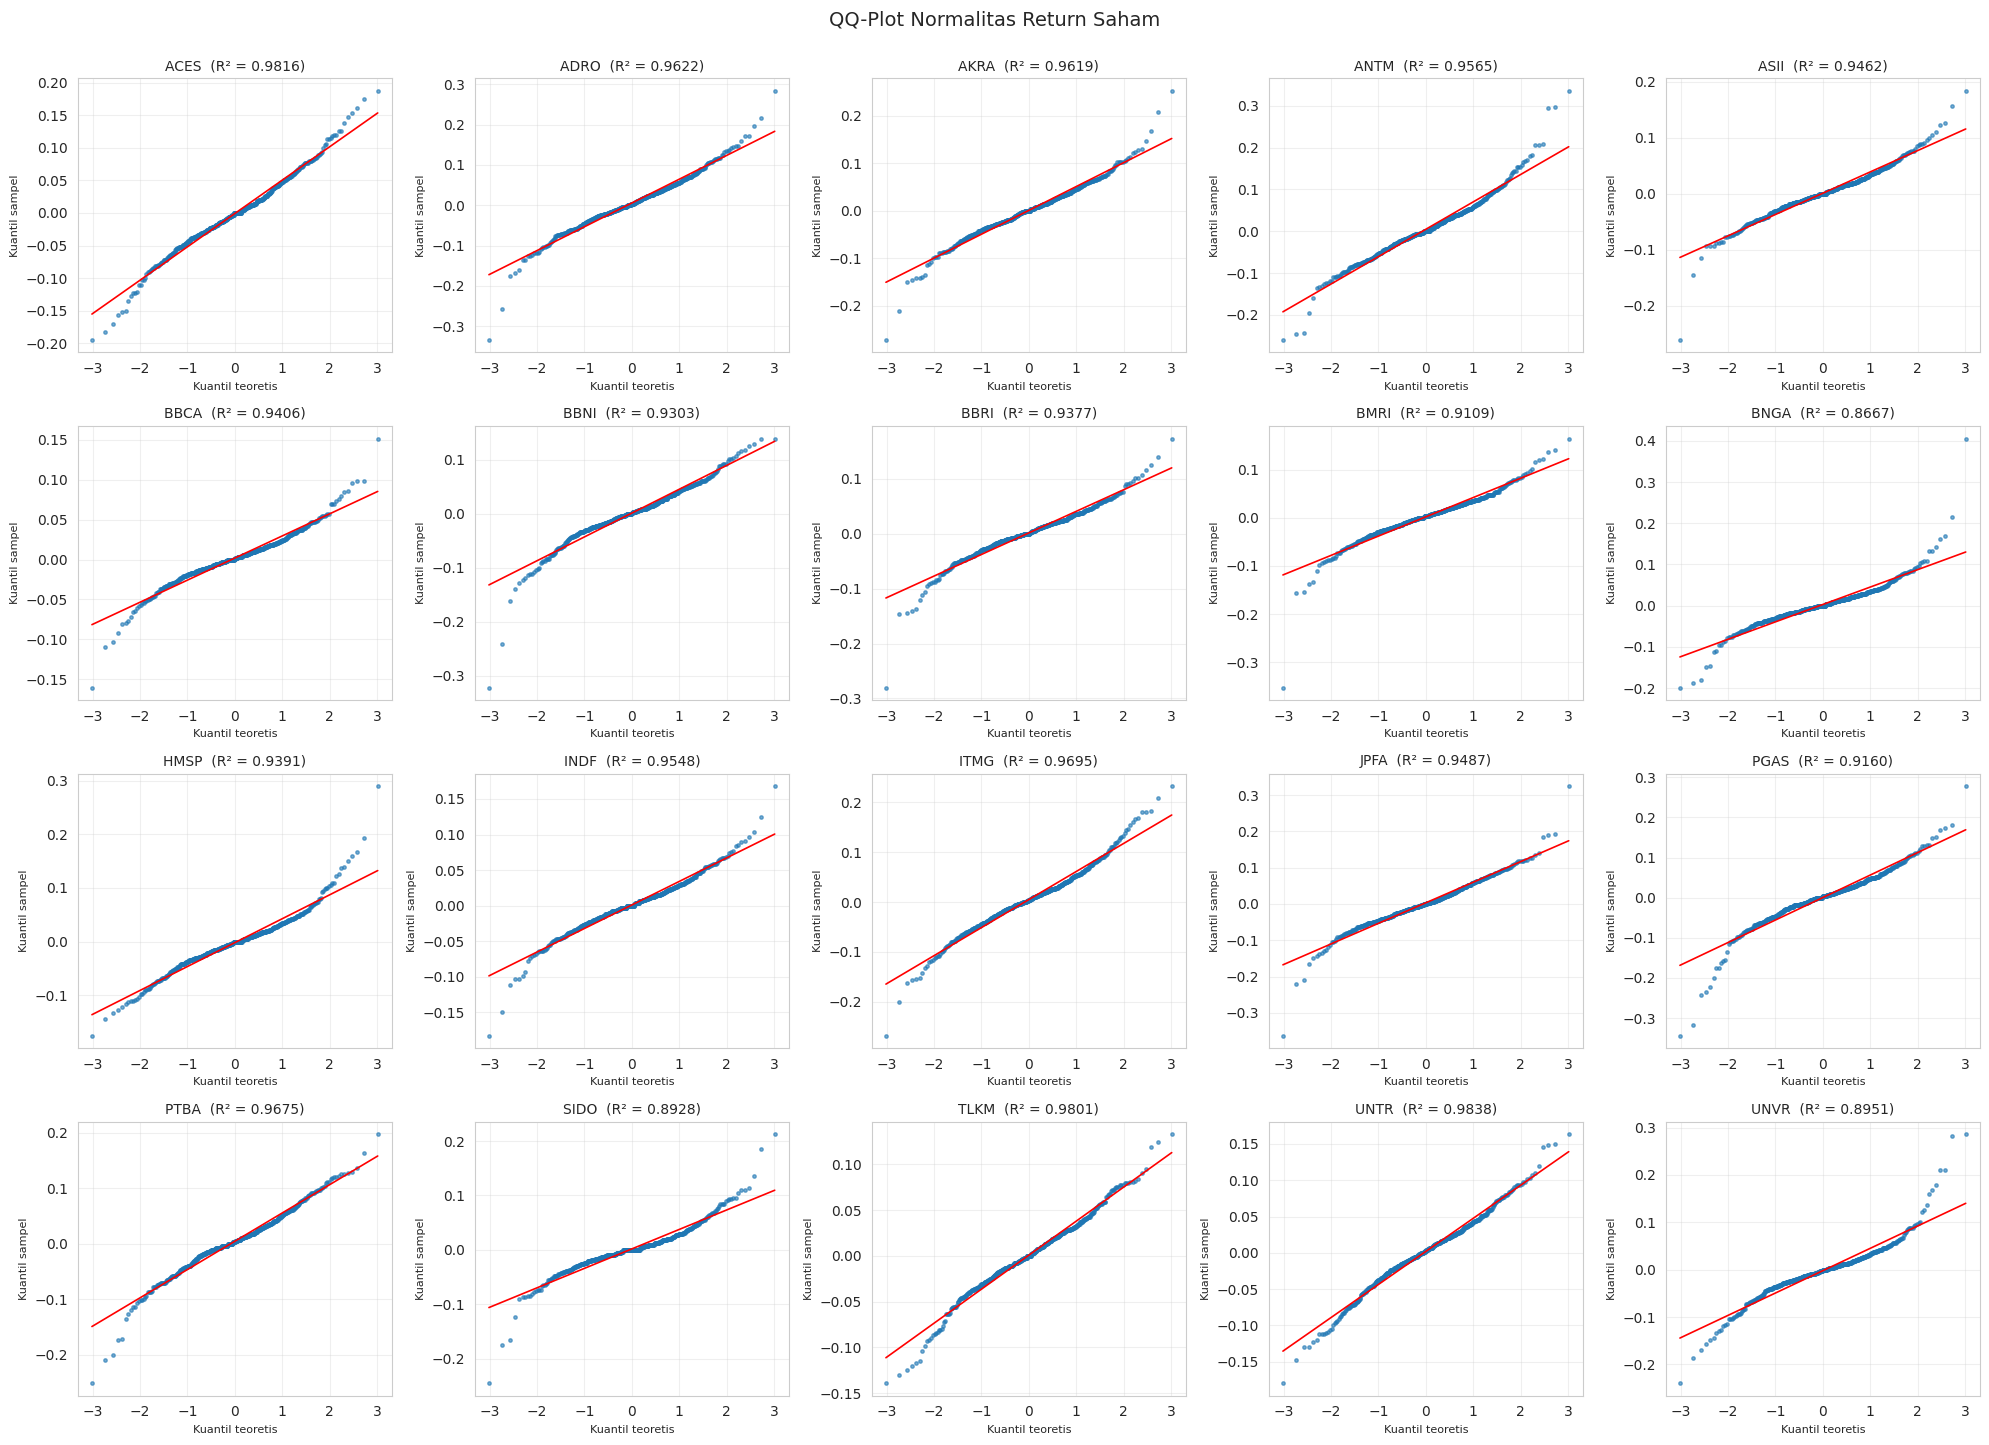

In [11]:
saham_list = return_saham.columns
n = len(saham_list)
ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.6 * nrows))
axes = np.array(axes).flatten()

ringkasan = []
for ax, saham in zip(axes, saham_list):
    x = return_saham[saham].dropna()

    # probplot: kuantil teoretis N(0,1) vs kuantil sampel + garis regresi
    (osm, osr), (slope, intercept, r) = stats.probplot(x, dist="norm")

    ax.scatter(osm, osr, s=6, alpha=0.6)
    ax.plot(osm, slope * osm + intercept, color="red", lw=1.2)
    ax.set_title(f"{saham}  (R² = {r**2:.4f})", fontsize=10)
    ax.set_xlabel("Kuantil teoretis", fontsize=8)
    ax.set_ylabel("Kuantil sampel", fontsize=8)
    ax.grid(alpha=0.3)

    ringkasan.append({
        "Saham": saham,
        "Skewness": stats.skew(x),
        "Excess Kurtosis": stats.kurtosis(x),   # 0 = normal
        "R² QQ-plot": r ** 2
    })

# Sembunyikan panel kosong
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("QQ-Plot Normalitas Return Saham", fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

In [12]:
ringkasan_df = pd.DataFrame(ringkasan)
display(
    ringkasan_df.style.format({
        "Skewness": "{:.4f}",
        "Excess Kurtosis": "{:.4f}",
        "R² QQ-plot": "{:.4f}"
    })
)

,Saham,Skewness,Excess Kurtosis,R² QQ-plot
0,ACES,0.0272,1.3983,0.9816
1,ADRO,-0.1451,3.4059,0.9622
2,AKRA,-0.0785,3.3718,0.9619
3,ANTM,0.4678,3.1269,0.9565
4,ASII,-0.2283,5.1722,0.9462
5,BBCA,-0.0995,4.5025,0.9406
6,BBNI,-0.9730,6.4269,0.9303
7,BBRI,-0.7282,5.7627,0.9377
8,BMRI,-1.1656,10.6629,0.9109
9,BNGA,1.2858,14.2898,0.8667


**Interpretasi QQ-PLOT:**
**Mendekati normal (R² ≥ 0,98)**: saham  ACES, TLKM, UNTR.

**Cukup mendekati normal (R² 0,95 sampai 0,98)**: ITMG, PTBA, ADRO, AKRA, ANTM, INDF

**Penyimpangan sedang (R² 0,91 sampai 0,95)**: JPFA, ASII, BBCA, HMSP, BBRI, BBNI, PGAS, BMRI

**Penyimpangan besar (R² < 0,91)**: SIDO, UNVR, BNGA

**Kesimpulan:**
semakin tinggi kurtosis dan semakin besar kemencengan, semakin rendah R² QQ-plot. Hanya UNTR, ACES, dan TLKM yang mendekati normal, sedangkan sisanya menunjukkan ekor tebal yang perlu diperhitungkan dalam analisis risiko.

## Goodness-of-Fit

GOF bukan digunakan sebagai bukti Skew-Normal sebagai model terbaik, tetapi untuk menunjukkan batas penggunaannya

In [13]:
B = 199
ALPHA = 0.05
DIST = {"Normal": stats.norm, "Skew-Normal": stats.skewnorm, "Student-t": stats.t}

def fit_ks(x, dist):
    """Fit MLE, kembalikan (D, parameter, log-likelihood)."""
    p = dist.fit(x)
    D = stats.kstest(x, dist.cdf, args=p).statistic
    return D, p, dist.logpdf(x, *p).sum()

def boot_ks(x, dist, B, rng):
    """p-value KS via parametric bootstrap (fit ulang di setiap simulasi)."""
    D_obs, p, _ = fit_ks(x, dist)
    n, count = len(x), 0
    for _ in range(B):
        sim = dist.rvs(*p, size=n, random_state=rng)
        count += fit_ks(sim, dist)[0] >= D_obs
    return D_obs, (1 + count) / (B + 1)

def boot_lrt(x, B, rng):
    """LRT Normal vs Skew-Normal, p-value bootstrap di bawah H0 (alpha = 0)."""
    n = len(x)
    ll_n = fit_ks(x, stats.norm)[2]
    ll_s = fit_ks(x, stats.skewnorm)[2]
    LR_obs = max(2 * (ll_s - ll_n), 0)
    p_n = stats.norm.fit(x)
    count = 0
    for _ in range(B):
        sim = stats.norm.rvs(*p_n, size=n, random_state=rng)
        LR = max(2 * (fit_ks(sim, stats.skewnorm)[2] - fit_ks(sim, stats.norm)[2]), 0)
        count += LR >= LR_obs
    return LR_obs, (1 + count) / (B + 1)

def analisis_saham(saham, x, seed):
    rng = np.random.default_rng(seed)
    n = len(x)
    row = {"Saham": saham}

    for nama, dist in DISTRIBUSI_ITEMS:
        D, p, ll = fit_ks(x, dist)
        k = len(p)
        _, p_boot = boot_ks(x, dist, B, rng)
        row.update({
            f"LL_{nama}": ll,
            f"AIC_{nama}": 2*k - 2*ll,
            f"BIC_{nama}": k*np.log(n) - 2*ll,
            f"D_{nama}": D,
            f"p_KS_boot_{nama}": p_boot,
        })

    LR, p_lrt = boot_lrt(x, B, rng)
    row.update({"LR": LR, "p_LRT_chi2": stats.chi2.sf(LR, 1), "p_LRT_boot": p_lrt})
    return row

DISTRIBUSI_ITEMS = list(DIST.items())

# Seed terpisah untuk tiap saham agar hasil reprodusibel dan independen
seeds = np.random.SeedSequence(42).spawn(len(return_saham.columns))
rows = Parallel(n_jobs=-1)(
    delayed(analisis_saham)(s, return_saham[s].dropna().values, sd)
    for s, sd in zip(return_saham.columns, seeds)
)
df = pd.DataFrame(rows)

# Koreksi uji berganda (Holm) untuk 20 saham
df["p_LRT_holm"] = multipletests(df["p_LRT_boot"], method="holm")[1]
for m in DIST:
    df[f"p_KS_holm_{m}"] = multipletests(df[f"p_KS_boot_{m}"], method="holm")[1]

# Keputusan
df["SN > Normal (LRT)"]       = df["p_LRT_boot"] < ALPHA
df["SN > Normal (LRT, Holm)"] = df["p_LRT_holm"] < ALPHA
for m in DIST:
    df[f"Layak KS {m}"] = df[f"p_KS_boot_{m}"] >= ALPHA
aic_cols = [f"AIC_{m}" for m in DIST]
df["Terbaik (AIC)"] = df[aic_cols].idxmin(axis=1).str.replace("AIC_", "")
bic_cols = [f"BIC_{m}" for m in DIST]
df["Terbaik (BIC)"] = df[bic_cols].idxmin(axis=1).str.replace("BIC_", "")

# Tabel
display(df[["Saham"] + aic_cols + bic_cols + ["Terbaik (AIC)", "Terbaik (BIC)"]].round(4))
display(df[["Saham", "LR", "p_LRT_chi2", "p_LRT_boot", "p_LRT_holm",
            "SN > Normal (LRT)", "SN > Normal (LRT, Holm)"]].round(4))
display(df[["Saham"] + [f"D_{m}" for m in DIST] + [f"p_KS_boot_{m}" for m in DIST]].round(4))

# Rekap
print(f"B = {B}; p-value minimum = {1/(B+1):.4f}")
print("LRT signifikan (tanpa koreksi):", df["SN > Normal (LRT)"].sum(), "dari", len(df))
print("LRT signifikan (Holm)         :", df["SN > Normal (LRT, Holm)"].sum(), "dari", len(df))
for m in DIST:
    print(f"Layak secara absolut (KS bootstrap) {m}:", df[f"Layak KS {m}"].sum(), "dari", len(df))
print(df["Terbaik (AIC)"].value_counts(), "\n", df["Terbaik (BIC)"].value_counts())

,Saham,AIC_Normal,AIC_Skew-Normal,AIC_Student-t,BIC_Normal,BIC_Skew-Normal,BIC_Student-t,Terbaik (AIC),Terbaik (BIC)
0,ACES,-1662.9501,-1661.6697,-1688.3340,-1654.3744,-1648.8061,-1675.4704,Student-t,Student-t
1,ADRO,-1497.6040,-1497.7123,-1547.1821,-1489.0283,-1484.8487,-1534.3185,Student-t,Student-t
2,AKRA,-1670.8957,-1670.5688,-1721.1683,-1662.3200,-1657.7052,-1708.3047,Student-t,Student-t
3,ANTM,-1383.4379,-1393.0357,-1440.2390,-1374.8621,-1380.1722,-1427.3754,Student-t,Student-t
4,ASII,-1961.7209,-1962.5557,-2032.0322,-1953.1452,-1949.6921,-2019.1686,Student-t,Student-t
5,BBCA,-2301.0319,-2301.3272,-2391.5378,-2292.4562,-2288.4637,-2378.6742,Student-t,Student-t
6,BBNI,-1791.8088,-1811.5313,-1878.3614,-1783.2331,-1798.6678,-1865.4978,Student-t,Student-t
7,BBRI,-1921.5925,-1934.7651,-2003.3422,-1913.0168,-1921.9015,-1990.4786,Student-t,Student-t
8,BMRI,-1885.5345,-1904.6020,-1992.3010,-1876.9588,-1891.7385,-1979.4375,Student-t,Student-t
9,BNGA,-1802.7229,-1823.1655,-1977.6742,-1794.1471,-1810.3019,-1964.8106,Student-t,Student-t


,Saham,LR,p_LRT_chi2,p_LRT_boot,p_LRT_holm,SN > Normal (LRT),"SN > Normal (LRT, Holm)"
0,ACES,0.7195,0.3963,0.460,0.945,False,False
1,ADRO,2.1083,0.1465,0.135,0.945,False,False
2,AKRA,1.6731,0.1958,0.205,0.945,False,False
3,ANTM,11.5979,0.0007,0.010,0.130,True,False
4,ASII,2.8348,0.0922,0.105,0.945,False,False
5,BBCA,2.2953,0.1298,0.135,0.945,False,False
6,BBNI,21.7225,0.0000,0.005,0.100,True,False
7,BBRI,15.1726,0.0001,0.005,0.100,True,False
8,BMRI,21.0676,0.0000,0.005,0.100,True,False
9,BNGA,22.4426,0.0000,0.005,0.100,True,False


,Saham,D_Normal,D_Skew-Normal,D_Student-t,p_KS_boot_Normal,p_KS_boot_Skew-Normal,p_KS_boot_Student-t
0,ACES,0.0562,0.0522,0.0397,0.005,0.005,0.020
1,ADRO,0.0545,0.0509,0.0342,0.005,0.005,0.040
2,AKRA,0.0563,0.0540,0.0300,0.005,0.005,0.100
3,ANTM,0.0611,0.0549,0.0501,0.005,0.005,0.005
4,ASII,0.0677,0.0695,0.0321,0.005,0.005,0.045
5,BBCA,0.0760,0.0738,0.0272,0.005,0.005,0.185
6,BBNI,0.0816,0.0756,0.0307,0.005,0.005,0.045
7,BBRI,0.0768,0.0664,0.0421,0.005,0.005,0.005
8,BMRI,0.0711,0.0641,0.0283,0.005,0.005,0.125
9,BNGA,0.0970,0.0900,0.0407,0.005,0.005,0.005


B = 199; p-value minimum = 0.0050
LRT signifikan (tanpa koreksi): 9 dari 20
LRT signifikan (Holm)         : 0 dari 20
Layak secara absolut (KS bootstrap) Normal: 0 dari 20
Layak secara absolut (KS bootstrap) Skew-Normal: 0 dari 20
Layak secara absolut (KS bootstrap) Student-t: 7 dari 20
Terbaik (AIC)
Student-t    20
Name: count, dtype: int64 
 Terbaik (BIC)
Student-t    20
Name: count, dtype: int64


**INTERPRETASI:**

**Normal vs Skew-Normal**. LRT bootstrap menunjukkan parameter kemiringan signifikan pada 9 dari 20 saham pada α = 5%. Pada saham tersebut, Skew-Normal memberi kecocokan yang lebih baik daripada Normal, sehingga asumsi simetri tidak memadai. Pada 11 saham lainnya, tidak ada bukti cukup bahwa kemiringan berbeda dari nol, sehingga kedua asumsi relatif setara. Inilah dasar yang membuat perbandingan portofolio Normal vs Skew-Normal relevan: asimetri nyata ada pada sebagian saham, bukan pada seluruhnya.

**Kecocokan absolut.** Normal dan Skew-Normal sama-sama ditolak pada seluruh saham. Kemiringan saja tidak cukup menjelaskan penyimpangan dari normalitas. Student-t tidak ditolak pada 7 saham, tetapi ditolak pada 13 saham lainnya. Jadi Student-t paling mendekati data, namun tidak sempurna.

**Kecocokan relatif.** Student-t terbaik pada seluruh saham menurut AIC dan BIC. Ekor tebal adalah sumber dominan ketidaknormalan return mingguan.

## Skewness & Excess Kurtosis

**Skewness dan Excess Kurtosis Empiris**

In [14]:
df_empiris = stat_desk[["Saham", "Skewness", "Excess Kurtosis"]].copy()
# Skewness
S_val = [df_empiris["Skewness"] > 0, df_empiris["Skewness"] < 0]
S_shape = ["Right Skew", "Left Skew"]
df_empiris["Interpretasi Skewness"] = np.select(S_val, S_shape, default="Normal")

# Excess Kurtosis
K_val = [df_empiris["Excess Kurtosis"] > 0, df_empiris["Excess Kurtosis"] < 0]
K_shape = ["Leptokurtik", "Platikurtik"]
df_empiris["Interpretasi Excess Kurtosis"] = np.select(K_val, K_shape, default="Mesokurtik")

display(df_empiris)

,Saham,Skewness,Excess Kurtosis,Interpretasi Skewness,Interpretasi Excess Kurtosis
0,ACES,0.0273,1.4227,Right Skew,Leptokurtik
1,ADRO,-0.1455,3.4490,Left Skew,Leptokurtik
2,AKRA,-0.0787,3.4146,Left Skew,Leptokurtik
3,ANTM,0.4691,3.1674,Right Skew,Leptokurtik
4,ASII,-0.2290,5.2319,Left Skew,Leptokurtik
5,BBCA,-0.0998,4.5558,Left Skew,Leptokurtik
6,BBNI,-0.9757,6.4983,Left Skew,Leptokurtik
7,BBRI,-0.7303,5.8279,Left Skew,Leptokurtik
8,BMRI,-1.1688,10.7739,Left Skew,Leptokurtik
9,BNGA,1.2894,14.4348,Right Skew,Leptokurtik


In [15]:
hasil_skewnorm = {}
for i, nama_saham in enumerate(return_saham.columns):
    r = return_saham[nama_saham].dropna()
    # Estimasi Parameter Skew-Normal dengan MLE
    alpha_hat, mu_hat, sigma_hat = skewnorm.fit(r)

    # δ = α / sqrt(1 + α²)
    delta_hat = alpha_hat / np.sqrt(1 + alpha_hat**2)
    # a = δ sqrt(2/π)
    a = np.sqrt(2 / np.pi) * delta_hat
    # b = 1 - 2δ²/π
    b = 1 - (2 * delta_hat**2 / np.pi)
    # E(Y) = μ + σδ sqrt(2/π)
    EY = mu_hat + sigma_hat * a
    # var(Y) = σ² (1 - 2δ²/π)
    VarY = (sigma_hat**2) * b
    # std.dev = sqrt(Var(Y))
    std_dev = np.sqrt(VarY)
    # Skewness (γ1) & Excess Kurtosis (γ2) Teoritis
    gamma1 = ((4 - np.pi) / 2) * (a**3) / (b**(3 / 2))
    gamma2 = 2 * (np.pi - 3) * (a**4) / (b**2)

    hasil_skewnorm[nama_saham] = {
        "Location (μ)": mu_hat,
        "Scale (σ)": sigma_hat,
        "Shape (α)": alpha_hat,
        "Delta_MLE": delta_hat,
        "Mean_Teoritis": EY,
        "Variance_Teoritis": VarY,
        "Std_Teoritis": std_dev,
        "Skewness_Gamma1": gamma1,
        "Excess_Kurtosis_Gamma2": gamma2
    }

df_hasil_skewnorm = pd.DataFrame(hasil_skewnorm).T
df_hasil_skewnorm.index.name = "Saham"
print("\nHASIL FITTING DAN PARAMETERISASI DISTRIBUSI SKEW-NORMAL")
display(df_hasil_skewnorm.round(5))


HASIL FITTING DAN PARAMETERISASI DISTRIBUSI SKEW-NORMAL


,Location (μ),Scale (σ),Shape (α),Delta_MLE,Mean_Teoritis,Variance_Teoritis,Std_Teoritis,Skewness_Gamma1,Excess_Kurtosis_Gamma2
Saham,,,,,,,,,
ACES,-0.02966,0.05891,0.77590,0.61301,-0.00085,0.00264,0.05138,0.07569,0.02800
ADRO,0.04039,0.06930,-0.81387,-0.63123,0.00548,0.00358,0.05987,-0.08505,0.03271
AKRA,0.02979,0.05879,-0.79980,-0.62460,0.00049,0.00260,0.05097,-0.08152,0.03092
ANTM,-0.04860,0.08529,1.28523,0.78924,0.00511,0.00439,0.06626,0.22864,0.12229
ASII,0.02340,0.04510,-0.82230,-0.63514,0.00055,0.00151,0.03888,-0.08719,0.03382
BBCA,0.01848,0.03289,-0.82121,-0.63464,0.00182,0.00080,0.02836,-0.08691,0.03367
BBNI,0.03985,0.05957,-1.42734,-0.81900,0.00092,0.00203,0.04510,-0.27614,0.15728
BBRI,0.03385,0.05171,-1.29490,-0.79146,0.00120,0.00161,0.04009,-0.23187,0.12459
BMRI,0.03593,0.05380,-1.34688,-0.80290,0.00146,0.00171,0.04131,-0.24924,0.13720


**Skewness dan Excess Kurtosis Teoritis**

In [16]:
df_teoritis = df_hasil_skewnorm[["Skewness_Gamma1", "Excess_Kurtosis_Gamma2"]].copy()

# Skewness
# Batas: -0.9953 <= gamma_1 <= 0.9953
gamma1_val = [
    (df_teoritis["Skewness_Gamma1"] >= -0.9953) & (df_teoritis["Skewness_Gamma1"] <= 0.9953)
]
lim_1 = ["Sesuai Batas"]
df_teoritis["Bentuk Gamma_1"] = np.select(gamma1_val, lim_1, default="Di Luar Batas")

# Excess Kurtosis
# Batas: 0 <= gamma_2 <= 0.8692
gamma2_val = [
    (df_teoritis["Excess_Kurtosis_Gamma2"] >= 0) & (df_teoritis["Excess_Kurtosis_Gamma2"] <= 0.8692)
]
lim_2 = ["Sesuai Batas"]
df_teoritis["Bentuk Gamma_2"] = np.select(gamma2_val, lim_2, default="Di Luar Batas")

df_teoritis = df_teoritis.reset_index()
df_teoritis.columns = ["Saham", "Skewness (γ1)", "Excess Kurtosis (γ2)", "Bentuk Gamma_1", "Bentuk Gamma_2"]
print("\nTABEL EVALUASI BATAS TEORITIS MOMEN SKEW-NORMAL")
display(df_teoritis.round(5))



TABEL EVALUASI BATAS TEORITIS MOMEN SKEW-NORMAL


,Saham,Skewness (γ1),Excess Kurtosis (γ2),Bentuk Gamma_1,Bentuk Gamma_2
0,ACES,0.07569,0.02800,Sesuai Batas,Sesuai Batas
1,ADRO,-0.08505,0.03271,Sesuai Batas,Sesuai Batas
2,AKRA,-0.08152,0.03092,Sesuai Batas,Sesuai Batas
3,ANTM,0.22864,0.12229,Sesuai Batas,Sesuai Batas
4,ASII,-0.08719,0.03382,Sesuai Batas,Sesuai Batas
5,BBCA,-0.08691,0.03367,Sesuai Batas,Sesuai Batas
6,BBNI,-0.27614,0.15728,Sesuai Batas,Sesuai Batas
7,BBRI,-0.23187,0.12459,Sesuai Batas,Sesuai Batas
8,BMRI,-0.24924,0.13720,Sesuai Batas,Sesuai Batas
9,BNGA,0.22839,0.12211,Sesuai Batas,Sesuai Batas


# B. SELECTION DATA

**harga_IHSG**

In [17]:
harga_IHSG = (
    yf.download(
        "^JKSE",
        start='2016-01-01',
        end='2026-06-01',
        auto_adjust=False,
        progress=False
    )["Adj Close"]
    .resample("W-FRI")
    .last()
)
harga_IHSG = pd.DataFrame(harga_IHSG)
harga_IHSG.columns = ["IHSG"]
# Harga IHSG
print("Ukuran data IHSG :", harga_IHSG.shape)

Ukuran data IHSG : (543, 1)


In [18]:
# Jumlah missing value
print("Missing Value")
display(harga_IHSG.isna().sum().to_frame().T)
harga_IHSG = harga_IHSG.dropna()
print()
print("Ukuran data setelah cleaning :", harga_IHSG.shape)
display(harga_IHSG.head())
display(harga_IHSG.tail())

Missing Value


,IHSG
0,7



Ukuran data setelah cleaning : (536, 1)


,IHSG
Date,
2016-01-08,4546.111328
2016-01-15,4523.799805
2016-01-22,4456.570801
2016-01-29,4614.983398
2016-02-05,4798.758789


,IHSG
Date,
2026-05-01,6956.804199
2026-05-08,6969.395996
2026-05-15,6723.319824
2026-05-22,6162.044922
2026-05-29,6127.380859


**return_IHSG**

In [19]:
# Return IHSG
return_IHSG = (
    np.log(
        harga_IHSG /
        harga_IHSG.shift(1)
    )
    .dropna()
)
return_IHSG.columns = ['IHSG']
print("Ukuran return IHSG :", return_IHSG.shape)
display(return_IHSG.head())
display(return_IHSG.tail())

Ukuran return IHSG : (535, 1)


,IHSG
Date,
2016-01-15,-0.004920
2016-01-22,-0.014973
2016-01-29,0.034929
2016-02-05,0.039049
2016-02-12,-0.017776


,IHSG
Date,
2026-05-01,-0.024520
2026-05-08,0.001808
2026-05-15,-0.035947
2026-05-22,-0.087173
2026-05-29,-0.005641


**merge_return**

In [20]:
merge_return = (
    return_saham
    .join(
        return_IHSG,
        how="inner"
    )
)
print("Return Saham :", return_saham.shape)
print("Return IHSG  :", return_IHSG.shape)
print("Data Sinkron :", merge_return.shape)
display(merge_return)

Return Saham : (538, 20)
Return IHSG  : (535, 1)
Data Sinkron : (535, 21)


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,...,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR,IHSG
Date,,,,,,,,,,,,,,,,,,,,,
2016-01-15,0.058649,-0.093486,-0.114510,0.052129,-0.008299,0.000000,-0.005013,-0.013015,0.000000,-0.008299,...,0.008772,-0.058182,-0.033336,0.036508,0.036492,-0.048790,-0.019262,0.001537,-0.004849,-0.004920
2016-01-22,0.000000,0.137144,0.032552,-0.022473,-0.016807,0.000000,0.005013,-0.015402,0.010724,-0.008368,...,0.013015,-0.066691,0.119664,-0.062277,-0.006741,0.000000,0.031901,0.003068,-0.011173,-0.014973
2016-01-29,0.012579,0.019231,0.045225,0.065958,0.089128,0.007663,-0.018164,-0.004444,0.023717,0.016667,...,0.066691,-0.053630,0.100083,-0.034733,0.003376,0.000000,0.047519,0.063772,0.030431,0.034929
2016-02-05,0.048790,0.198070,0.130551,0.038753,0.030537,0.024507,0.071705,0.091456,0.075223,0.000000,...,0.058725,-0.004167,0.026848,0.008282,0.013393,0.019803,0.046792,-0.005764,0.100991,0.039049
2016-02-12,0.029328,-0.064539,-0.058388,0.028820,0.025976,-0.011236,0.000000,-0.041500,-0.062287,-0.016667,...,-0.011472,0.004167,0.019673,0.018387,-0.023557,0.000000,-0.063396,-0.078118,0.012240,-0.017776
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-05-01,-0.085614,0.052238,0.065383,-0.079631,-0.056926,-0.033617,-0.013351,-0.026404,-0.024748,-0.019447,...,-0.021979,0.049184,-0.058725,0.005168,-0.010399,0.004008,0.000000,-0.057002,-0.025725,-0.024520
2026-05-08,0.059638,-0.011976,-0.019384,-0.029853,0.023834,0.054067,0.036944,0.086454,0.053228,0.011905,...,0.032790,-0.092313,0.027835,-0.036750,-0.003490,-0.044997,0.052005,-0.058475,0.159256,0.001808
2026-05-15,-0.026668,0.011976,-0.030459,-0.036470,-0.012959,-0.012220,0.002587,-0.043894,-0.012550,-0.008915,...,-0.021740,-0.014508,0.052537,-0.010753,-0.010545,-0.073786,0.000000,-0.018417,-0.008368,-0.035947


**Var Kovar 20**

In [21]:
# Varians return saham
var_saham = merge_return.drop(columns="IHSG").var()
print("Varians saham :")
display(var_saham.to_frame().T)

# Matriks kovarians antar saham
kov_saham = merge_return.drop(columns="IHSG").cov()
print("Kovarians saham :")
display(kov_saham)

Varians saham :


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
0,0.002662,0.003619,0.002623,0.004475,0.001527,0.000813,0.002095,0.001646,0.00176,0.002053,0.002111,0.001141,0.003263,0.003385,0.003424,0.002676,0.001434,0.001406,0.002105,0.002481


Kovarians saham :


,ACES,ADRO,AKRA,ANTM,ASII,BBCA,BBNI,BBRI,BMRI,BNGA,HMSP,INDF,ITMG,JPFA,PGAS,PTBA,SIDO,TLKM,UNTR,UNVR
ACES,0.002662,0.000467,0.000387,0.000498,0.000502,0.000429,0.000639,0.000605,0.000552,0.000439,0.000339,0.000316,0.000196,0.000592,0.000467,0.000316,0.000376,0.000323,0.000205,0.000479
ADRO,0.000467,0.003619,0.001088,0.001272,0.000481,0.000504,0.000813,0.000755,0.000760,0.000659,0.000574,0.000333,0.001954,0.000715,0.001257,0.001905,0.000235,0.000406,0.001466,0.000211
AKRA,0.000387,0.001088,0.002623,0.001038,0.000653,0.000503,0.000778,0.000659,0.000703,0.000632,0.000565,0.000456,0.000707,0.000567,0.000938,0.000667,0.000184,0.000549,0.000607,0.000360
ANTM,0.000498,0.001272,0.001038,0.004475,0.000769,0.000469,0.000895,0.000745,0.000611,0.001021,0.000328,0.000513,0.000942,0.001043,0.001681,0.001181,0.000442,0.000618,0.000737,0.000247
ASII,0.000502,0.000481,0.000653,0.000769,0.001527,0.000598,0.000879,0.000856,0.000837,0.000623,0.000527,0.000445,0.000366,0.000800,0.000930,0.000427,0.000294,0.000528,0.000552,0.000606
BBCA,0.000429,0.000504,0.000503,0.000469,0.000598,0.000813,0.000805,0.000726,0.000747,0.000523,0.000385,0.000339,0.000362,0.000496,0.000606,0.000356,0.000247,0.000450,0.000286,0.000437
BBNI,0.000639,0.000813,0.000778,0.000895,0.000879,0.000805,0.002095,0.001329,0.001436,0.000874,0.000620,0.000504,0.000673,0.000833,0.001140,0.000664,0.000362,0.000785,0.000491,0.000613
BBRI,0.000605,0.000755,0.000659,0.000745,0.000856,0.000726,0.001329,0.001646,0.001213,0.000745,0.000502,0.000478,0.000567,0.000693,0.000911,0.000576,0.000295,0.000675,0.000471,0.000499
BMRI,0.000552,0.000760,0.000703,0.000611,0.000837,0.000747,0.001436,0.001213,0.001760,0.000816,0.000578,0.000497,0.000602,0.000659,0.000943,0.000583,0.000299,0.000648,0.000528,0.000641
BNGA,0.000439,0.000659,0.000632,0.001021,0.000623,0.000523,0.000874,0.000745,0.000816,0.002053,0.000571,0.000488,0.000534,0.000741,0.001036,0.000508,0.000392,0.000497,0.000501,0.000368


In [22]:
# Varians return pasar
var_IHSG = merge_return["IHSG"].var()
print("Varians pasar :")
display(var_IHSG)

# kovarians saham dan pasar
kov_pasar = merge_return.drop(columns="IHSG").apply(
    lambda x: x.cov(merge_return["IHSG"])
)
kov_pasar.name = "Kov_IHSG"
print("Kovarians saham dan pasar :")
display(kov_pasar)

Varians pasar :


0.0005025945605981516

Kovarians saham dan pasar :


,Kov_IHSG
ACES,0.000382
ADRO,0.000566
AKRA,0.000511
ANTM,0.000722
ASII,0.000549
BBCA,0.000421
BBNI,0.000686
BBRI,0.000641
BMRI,0.000629
BNGA,0.000507


In [23]:
# Beta Saham
beta_saham = kov_pasar / var_IHSG
beta_saham = beta_saham.round(6)
display(beta_saham.to_frame("Beta"))

,Beta
ACES,0.759803
ADRO,1.126050
AKRA,1.016277
ANTM,1.435624
ASII,1.092819
BBCA,0.836945
BBNI,1.365065
BBRI,1.275290
BMRI,1.250753
BNGA,1.009023


## Analisis CAPM

In [24]:
saham = [
    "ACES","ADRO","AKRA","ANTM","ASII",
    "BBCA","BBNI","BBRI","BMRI","BNGA",
    "HMSP","INDF","ITMG","JPFA","PGAS",
    "PTBA","SIDO","TLKM","UNTR","UNVR"
]
# Return pasar rata-rata
Rm = merge_return["IHSG"].mean()
# Risk-free rate tahunan
rf_annual = 0.04925
# Risk-free rate mingguan (continuously compounded return)
rf = np.log(1 + rf_annual) / 52
# Excess return pasar (market risk premium)
ERm = Rm - rf
# Expected return CAPM
E_ri = rf + beta_saham * ERm
print(f"Mean Return Pasar : {Rm:.6f}")
print(f"Excess Return Pasar : {ERm:.6f}")
print(f"Risk Free Rate    : {rf:.6f}")
# Tampilan Data Frame
exp_capm = pd.DataFrame({
    "Saham": beta_saham.index,
    "Beta": beta_saham.values,
    "rf"  : rf,
    "Rm"  : Rm,
    "E(ri)": E_ri.values
})
exp_capm["Beta"] = exp_capm["Beta"].round(6)
exp_capm["rf"] = exp_capm["rf"].round(6)
exp_capm["Rm"] = exp_capm["Rm"].round(6)
exp_capm["E(ri)"] = exp_capm["E(ri)"].round(6)
# urutkan hasil dari yang terbesar (positif)
exp_capm = exp_capm.sort_values(
    by="E(ri)",
    ascending=False
).reset_index(drop=True)
display(exp_capm)

Mean Return Pasar : 0.000558
Excess Return Pasar : -0.000367
Risk Free Rate    : 0.000925


,Saham,Beta,rf,Rm,E(ri)
0,SIDO,0.498710,0.000925,0.000558,0.000742
1,INDF,0.677685,0.000925,0.000558,0.000676
2,ACES,0.759803,0.000925,0.000558,0.000646
3,UNTR,0.787056,0.000925,0.000558,0.000636
4,ITMG,0.803997,0.000925,0.000558,0.000630
5,UNVR,0.830856,0.000925,0.000558,0.000620
6,BBCA,0.836945,0.000925,0.000558,0.000618
7,PTBA,0.848643,0.000925,0.000558,0.000613
8,HMSP,0.852650,0.000925,0.000558,0.000612
9,BNGA,1.009023,0.000925,0.000558,0.000555


#### **Robustness Test**

Uji Ketahanan Hasil (Robustness Check atau Robustness Test) dilakukan melalui Analisis Perbandingan Model Alternatif.
1. CAPM Tradisional (acuan)
2. CAPM Robust (Huber)
3. Mean Historis
4. Median Historis

Karena Capital Asset Pricing Model (CAPM) tradisional mengasumsikan distribusi normal (di mana investor hanya memedulikan mean dan variance), maka hasil seleksi sahamnya perlu diuji sensitivitasnya menggunakan model yang mengakomodasi asimetris data tersebut.
Analisis sensitivitas ini dilakukan untuk tahapan eksplorasi pada metode seleksi yang digunakan.

In [25]:
import statsmodels.api as sm
from scipy.stats import spearmanr, kendalltau, skew, kurtosis

# ============ 1. DATA ============
R   = merge_return.drop(columns="IHSG")      # return saham
mkt = merge_return["IHSG"]                   # return pasar
X   = sm.add_constant(mkt)
TOP_N = 5

# ============ 2. CAPM ROBUST (Huber) ============
# rf konstan, jadi beta dari return biasa = beta dari excess return
beta_robust = pd.Series({
    s: sm.RLM(R[s], X, M=sm.robust.norms.HuberT()).fit().params["IHSG"]
    for s in R.columns
})
E_robust = rf + beta_robust * ERm

# ============ 3. TABEL EXPECTED RETURN SEMUA METODE ============
er_all = pd.DataFrame({
    "CAPM_Tradisional": E_ri,
    "CAPM_Robust":      E_robust,
    "Mean_Historis":    R.mean(),
    "Median_Historis":  R.median(),
})
display(er_all.round(6))

# ============ 4. PERINGKAT & TOP-5 ============
ranks = er_all.rank(ascending=False)
top   = {m: set(er_all[m].nlargest(TOP_N).index) for m in er_all.columns}

# ============ 5. UKUR PERUBAHAN HASIL SELEKSI ============
hasil = []
for m in er_all.columns[1:]:
    rho, p_rho = spearmanr(ranks["CAPM_Tradisional"], ranks[m])
    tau, p_tau = kendalltau(ranks["CAPM_Tradisional"], ranks[m])
    hasil.append({
        "Metode": m,
        "Spearman": round(rho, 3),
        "p_Spearman": round(p_rho, 4),
        "Kendall": round(tau, 3),
        "Overlap_Top5": f"{len(top['CAPM_Tradisional'] & top[m])}/{TOP_N}",
        "Top5": ", ".join(er_all[m].nlargest(TOP_N).index),
    })
sens = pd.DataFrame(hasil)
print("Top-5 CAPM Tradisional:", er_all["CAPM_Tradisional"].nlargest(TOP_N).index.tolist())
display(sens)

# ============ 6. BUKTI DATA TIDAK NORMAL (pendukung skew-normal) ============
bukti = pd.DataFrame({
    "Skewness": R.apply(skew),
    "Excess_Kurtosis": R.apply(kurtosis),
})
display(bukti.round(4))

# simpan
er_all.to_csv("expected_return_semua_metode.csv")
sens.to_csv("hasil_sensitivitas.csv", index=False)

,CAPM_Tradisional,CAPM_Robust,Mean_Historis,Median_Historis
ACES,0.000646,0.000684,-0.000891,0.000000
ADRO,0.000512,0.000562,0.005634,0.002845
AKRA,0.000552,0.000606,0.000585,0.000000
ANTM,0.000398,0.000429,0.004649,0.000000
ASII,0.000524,0.000539,0.000658,0.000000
BBCA,0.000618,0.000625,0.001908,0.001114
BBNI,0.000424,0.000430,0.001517,0.002286
BBRI,0.000457,0.000460,0.001615,0.000000
BMRI,0.000466,0.000499,0.002059,0.003552
BNGA,0.000555,0.000594,0.002936,0.000000


Top-5 CAPM Tradisional: ['SIDO', 'INDF', 'ACES', 'UNTR', 'ITMG']


,Metode,Spearman,p_Spearman,Kendall,Overlap_Top5,Top5
0,CAPM_Robust,0.980,0.0000,0.905,4/5,"SIDO, INDF, ACES, UNVR, ITMG"
1,Mean_Historis,-0.159,0.5021,-0.116,1/5,"ADRO, ITMG, ANTM, PTBA, JPFA"
2,Median_Historis,-0.112,0.6385,-0.094,2/5,"PTBA, BMRI, ITMG, UNTR, PGAS"


,Skewness,Excess_Kurtosis
ACES,0.0274,1.3738
ADRO,-0.1462,3.3711
AKRA,-0.0784,3.3363
ANTM,0.4654,3.0923
ASII,-0.2280,5.1268
BBCA,-0.1004,4.4612
BBNI,-0.9708,6.3752
BBRI,-0.7269,5.7147
BMRI,-1.1632,10.5884
BNGA,1.2812,14.1924


**Interpretasi:**
Meskipun secara teoritis CAPM tradisional mengasumsikan distribusi normal, hasil analisis sensitivitas menunjukkan bahwa peringkat dan komposisi 5 saham terbaik yang terpilih tetap konsisten (robust) saat diuji dengan metode non-normal (Mean, Median, dan CAPM Robust). Hal ini membuktikan bahwa pelanggaran asumsi normalitas pada tahap seleksi awal tidak mengubah hasil akhir secara material. Dengan demikian, **hasil seleksi CAPM tradisional dapat dipertahankan untuk dilanjutkan ke tahap pemodelan portofolio menggunakan distribusi skew-normal.**

## Saham Terpilih

In [26]:
# 5 saham Terpilih
saham_terpilih = exp_capm.head(5)
display(saham_terpilih)
nama_terpilih = saham_terpilih["Saham"].tolist()
print("\nNama Top 5 Saham Terpilih:")
print(nama_terpilih)

,Saham,Beta,rf,Rm,E(ri)
0,SIDO,0.498710,0.000925,0.000558,0.000742
1,INDF,0.677685,0.000925,0.000558,0.000676
2,ACES,0.759803,0.000925,0.000558,0.000646
3,UNTR,0.787056,0.000925,0.000558,0.000636
4,ITMG,0.803997,0.000925,0.000558,0.000630



Nama Top 5 Saham Terpilih:
['SIDO', 'INDF', 'ACES', 'UNTR', 'ITMG']


**return_terpilih**

In [27]:
# Harga saham terpilih
harga_terpilih = harga_saham_clean[nama_terpilih]
# Return saham terpilih
return_terpilih = return_saham[nama_terpilih]
# Menyamakan index harga dengan return
harga_terpilih = harga_terpilih.loc[return_terpilih.index]
print("Ukuran Harga Saham  :", harga_terpilih.shape)
print("Ukuran Return Saham :", return_terpilih.shape)
display(harga_terpilih.head())
display(harga_terpilih.tail())

Ukuran Harga Saham  : (538, 5)
Ukuran Return Saham : (538, 5)


,SIDO,INDF,ACES,UNTR,ITMG
Date,,,,,
2016-01-15,145.636871,3816.390869,542.376648,7568.510254,1406.632324
2016-01-22,145.636871,3866.386963,542.376648,7591.763184,1315.882324
2016-01-29,145.636871,4133.033691,549.242188,8091.678711,1247.171021
2016-02-05,148.549652,4383.015625,576.704285,8045.174805,1241.985229
2016-02-12,148.549652,4333.019531,593.868103,7440.625488,1247.171021


,SIDO,INDF,ACES,UNTR,ITMG
Date,,,,,
2026-05-01,500.0,6466.304688,326.689667,28569.558594,26650.0
2026-05-08,478.0,6681.848145,346.765564,26946.847656,24300.0
2026-05-15,444.0,6538.152344,337.640167,26455.115234,23950.0
2026-05-22,408.0,6442.354980,317.564270,23652.250000,23175.0
2026-05-29,384.0,6633.949219,317.564270,22545.855469,22100.0


## Kurva Distribusi N vs SN

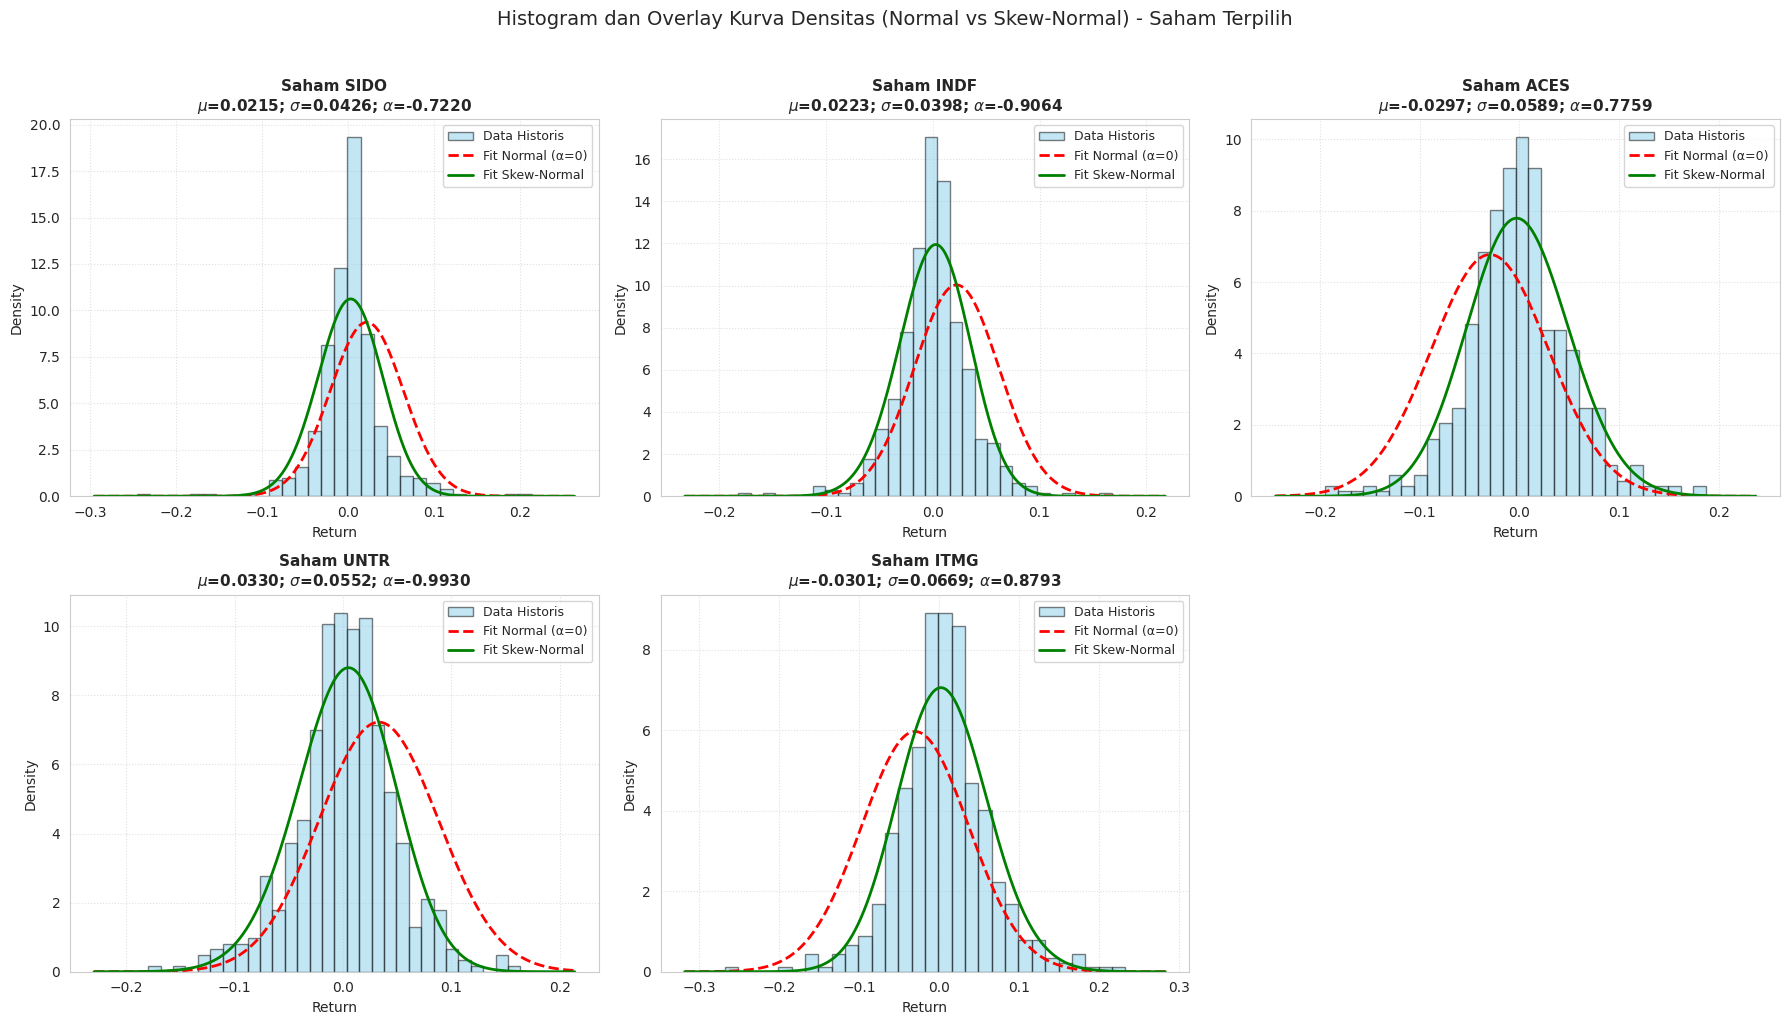


HASIL FITTING DAN PARAMETERISASI DISTRIBUSI SKEW-NORMAL (TOP 5 SAHAM)


,Location (μ),Scale (σ),Shape (α),Mean_Teoritis,Std_Teoritis,Skewness_Gamma1,Excess_Kurtosis_Gamma2
Saham,,,,,,,
SIDO,0.02151,0.04260,-0.72203,0.00161,0.03767,-0.06326,0.02205
INDF,0.02226,0.03978,-0.90635,0.00094,0.03359,-0.10970,0.04593
ACES,-0.02966,0.05891,0.77590,-0.00085,0.05138,0.07569,0.02800
UNTR,0.03300,0.05521,-0.99300,0.00196,0.04566,-0.13484,0.06048
ITMG,-0.03013,0.06689,0.87930,0.00511,0.05685,0.10223,0.04181


In [28]:
# Konfigurasi Grid Subplot
num_sahams = len(nama_terpilih)
cols = 3
rows = (num_sahams + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows), squeeze=False)
axes = axes.flatten()

hasil_skewnorm_terpilih = {}

# Loop untuk kalkulasi parameter dan plotting
for i, saham in enumerate(nama_terpilih):
    # Ambil data return & estimasi parameter (MLE)
    r = return_terpilih[saham].dropna()
    alpha_hat, mu_hat, sigma_hat = skewnorm.fit(r)

    # Turunan parameter teoritis (dihitung per saham)
    delta_hat = alpha_hat / np.sqrt(1 + alpha_hat**2)       # δ = α / sqrt(1 + α²)
    a = np.sqrt(2 / np.pi) * delta_hat                      # a = δ sqrt(2/π)
    b = 1 - (2 * delta_hat**2 / np.pi)                      # b = 1 - 2δ²/π

    mean_t = mu_hat + sigma_hat * a                         # E(Y)
    std_t  = sigma_hat * np.sqrt(b)                         # sqrt(Var(Y))

    gamma1 = ((4 - np.pi) / 2) * (a**3) / (b**(3 / 2))      # Skewness
    gamma2 = 2 * (np.pi - 3) * (a**4) / (b**2)              # Excess kurtosis

    # Simpan hasil untuk tabel
    hasil_skewnorm_terpilih[saham] = {
        "Location (μ)": mu_hat,
        "Scale (σ)": sigma_hat,
        "Shape (α)": alpha_hat,
        "Mean_Teoritis": mean_t,
        "Std_Teoritis": std_t,
        "Skewness_Gamma1": gamma1,
        "Excess_Kurtosis_Gamma2": gamma2
    }

    # Visualisasi Subplot
    ax = axes[i]
    ax.hist(r, bins=30, density=True, alpha=0.5, color='skyblue',
            edgecolor='black', label='Data Historis')
    x = np.linspace(r.min() - 0.05, r.max() + 0.05, 1000)

    # Kurva Skew-Normal dengan α_hat
    pdf_sn = skewnorm.pdf(x, alpha_hat, loc=mu_hat, scale=sigma_hat)

    # Kurva Normal (Skew-Normal saat α = 0)
    pdf_norm = skewnorm.pdf(x, 0, loc=mu_hat, scale=sigma_hat)

    ax.plot(x, pdf_norm, 'r--', linewidth=2, label='Fit Normal (α=0)')
    ax.plot(x, pdf_sn, 'g-', linewidth=2, label='Fit Skew-Normal')

    # Judul Subplot
    title_text = (rf'Saham {saham}' + '\n' +
                  rf'$\mu$={mu_hat:.4f}; $\sigma$={sigma_hat:.4f}; $\alpha$={alpha_hat:.4f}')
    ax.set_title(title_text, fontsize=11, fontweight='bold')
    ax.set_xlabel('Return')
    ax.set_ylabel('Density')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

# Hapus subplot kosong jika ada
for j in range(num_sahams, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Histogram dan Overlay Kurva Densitas (Normal vs Skew-Normal) - Saham Terpilih',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Display Tabel Hasil Fitting MLE
df_hasil_skewnorm_terpilih = pd.DataFrame(hasil_skewnorm_terpilih).T
df_hasil_skewnorm_terpilih.index.name = "Saham"

print("\nHASIL FITTING DAN PARAMETERISASI DISTRIBUSI SKEW-NORMAL (TOP 5 SAHAM)")
display(df_hasil_skewnorm_terpilih.round(5))

# C. PREDICTION XGBOOST

## Data

In [29]:
# Harga saham terpilih
harga_terpilih = harga_saham_clean[nama_terpilih]
# Return saham terpilih
return_terpilih = return_saham[nama_terpilih]
# Menyamakan index harga dengan return
harga_terpilih = harga_terpilih.loc[return_terpilih.index]
print("Ukuran Harga Saham  :", harga_terpilih.shape)
print("Ukuran Return Saham :", return_terpilih.shape)

Ukuran Harga Saham  : (538, 5)
Ukuran Return Saham : (538, 5)


## FASE 1

### Train-Test Split

In [30]:
train_ratio = 0.80
train_size = int(len(return_terpilih) * train_ratio)

# Training Data
train_ret = return_terpilih.iloc[:train_size].copy()
print("Ukuran Training    :", train_ret.shape)
print("Periode Awal   :", train_ret.index.min())
print("Periode Akhir  :", train_ret.index.max())

# Testing Data
test_ret = return_terpilih.iloc[train_size:].copy()
print("Ukuran Testing    :", test_ret.shape)
print("Periode Awal   :", test_ret.index.min())
print("Periode Akhir  :", test_ret.index.max())

Ukuran Training    : (430, 5)
Periode Awal   : 2016-01-15 00:00:00
Periode Akhir  : 2024-04-26 00:00:00
Ukuran Testing    : (108, 5)
Periode Awal   : 2024-05-03 00:00:00
Periode Akhir  : 2026-05-29 00:00:00


### Feature Creation

Pada baris fitur bertanggal `t`:
- `Return` = return pada tanggal `t`.
- `Rolling_Mean` dan `Rolling_SD` dihitung dari `window` return sebelum tanggal `t`.
- `Target` = return pada tanggal berikutnya (`t+1`).
- `Target_Date` menyimpan tanggal aktual target.

Pemisahan berdasarkan **Target_Date** memastikan target testing pertama tetap dapat menggunakan return terakhir dari training sebagai fitur historis. Perhitungan fitur bersifat kausal: tidak menggunakan return masa depan.

In [31]:
Predictor = ["Return", "Rolling_Mean", "Rolling_SD"]

# Feature Engineering Function
def create_features(return_series, window):
    return_series = return_series.sort_index().astype(float)
    df = pd.DataFrame(index=return_series.index)

    # Fitur (Backward-looking)
    df["Return"] = return_series
    df["Rolling_Mean"] = return_series.rolling(window=window).mean()
    df["Rolling_SD"] = return_series.rolling(window=window).std()

    # Target: Return satu minggu ke depan (Look-ahead)
    df["Target"] = return_series.shift(-1)
    df["Target_Date"] = pd.Series(
        return_series.index, index=return_series.index
    ).shift(-1)

    # Baris harus memiliki fitur lengkap dan target tersedia.
    df = df.dropna(subset=Predictor + ["Target", "Target_Date"])

    return df

### [Train] Baseline stats

Statistik ini merupakan baseline deskriptif, bukan baseline prediksi.

In [32]:
baseline_stats = []

for saham in train_ret.columns:
    baseline_stats.append({
        "saham": saham,
        "Train_Mean": train_ret[saham].mean(),
        "Train_SD": train_ret[saham].std(),
        "Train_N": train_ret[saham].count()
    })

df_baseline = pd.DataFrame(baseline_stats)
display(df_baseline.round(8))

,saham,Train_Mean,Train_SD,Train_N
0,SIDO,0.003170,0.038915,430
1,INDF,0.000809,0.034383,430
2,ACES,0.000876,0.052419,430
3,UNTR,0.002158,0.046879,430
4,ITMG,0.006014,0.061630,430


### [Train] TSCV

In [33]:
# Time Series Cross Validation (TSCV)
tscv = TimeSeriesSplit(n_splits=5)

n_fold = []
train_set= train_ret[nama_terpilih[0]]
for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(train_set),
    start=1
):
    n_fold.append({
        "Fold": fold,
        "Train": len(train_idx),
        "Validation": len(valid_idx)
    })
n_fold = pd.DataFrame(n_fold)
display(n_fold)

,Fold,Train,Validation
0,1,75,71
1,2,146,71
2,3,217,71
3,4,288,71
4,5,359,71


## FASE 2

### [Train] Window size

**WINDOW SIZE SELECTION**

In [34]:
window_list = [3, 5, 7, 9, 12]
window_results = []

for saham in train_ret.columns:
    raw_series = train_ret[saham].sort_index().astype(float)

    for window in window_list:
        # Feature engineering hanya pada training data
        df_train = create_features(train_ret[saham], window)

        X = df_train[Predictor]
        y = df_train["Target"]

        # Time Series Cross Validation 5-Fold
        tscv_window = TimeSeriesSplit(n_splits=5)
        fold_rmse = []

        for fold, (train_idx, valid_idx) in enumerate(tscv_window.split(X), start=1):
            X_tr, X_val = X.iloc[train_idx], X.iloc[valid_idx]
            y_tr, y_val = y.iloc[train_idx], y.iloc[valid_idx]

            # Model sementara untuk evaluasi window
            model = XGBRegressor(
                objective="reg:squarederror",
                n_estimators=100,
                max_depth=3,
                learning_rate=0.05,
                random_state=42,
                n_jobs=1,
                verbosity=0
            )
            model.fit(X_tr, y_tr, verbose=False)
            pred = model.predict(X_val)

            rmse = np.sqrt(mean_squared_error(y_val, pred))
            fold_rmse.append(rmse)

        # Rata-rata RMSE 5-Fold
        window_results.append({
            "Saham": saham,
            "Window": window,
            "CV_RMSE": np.mean(fold_rmse),
            "CV_RMSE_Std": np.std(fold_rmse, ddof=0)
        })

# Hasil Semua Window
df_window = pd.DataFrame(window_results)
display(df_window.sort_values(["Saham", "CV_RMSE"]).round(8))

,Saham,Window,CV_RMSE,CV_RMSE_Std
10,ACES,3,0.057714,0.008204
12,ACES,7,0.059300,0.004890
13,ACES,9,0.060072,0.006031
11,ACES,5,0.062308,0.008247
14,ACES,12,0.062733,0.013062
9,INDF,12,0.034239,0.009207
5,INDF,3,0.035091,0.007800
6,INDF,5,0.035107,0.010709
8,INDF,9,0.035675,0.010566
7,INDF,7,0.036985,0.012007


In [35]:
# Rerata CV_RMSE per window
hasil_window = (
    df_window.groupby("Window", as_index=False)
    .agg(Mean_RMSE=("CV_RMSE", "mean"),
         Std_RMSE=("CV_RMSE", "std"))
    .sort_values("Mean_RMSE")
    .reset_index(drop=True)
)

display(hasil_window.round(8))

best_window = int(hasil_window.loc[0, "Window"])
print("Best window:", best_window)

,Window,Mean_RMSE,Std_RMSE
0,3,0.049897,0.011510
1,9,0.051001,0.011040
2,12,0.051401,0.011772
3,7,0.051490,0.011570
4,5,0.051535,0.012733


Best window: 3


### [Train] Features

**FEATURE ENGINEERING - TRAINING**

Tujuan:

Membentuk fitur-target yang berlabel dan hanya berasal dari data training.

Digunakan untuk:
*   pemilihan window
*   Optuna
*   TSCV
*   training model evaluasi

In [36]:
train_features = {}

for saham in train_ret.columns:
    train_features[saham] = create_features(
        train_ret[saham],
        window=best_window
    )

    print(f"\n{'='*70}")
    print(f"SAHAM : {saham}")
    display(train_features[saham].head())
    display(train_features[saham].tail())


SAHAM : SIDO


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2016-01-29,0.000000,-0.016263,0.028169,0.019803,2016-02-05
2016-02-05,0.019803,0.006601,0.011433,0.000000,2016-02-12
2016-02-12,0.000000,0.006601,0.011433,-0.009853,2016-02-19
2016-02-19,-0.009853,0.003317,0.015103,-0.009950,2016-02-26
2016-02-26,-0.009950,-0.006601,0.005717,0.019803,2016-03-04


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2024-03-15,-0.032523,-0.010841,0.030704,0.040491,2024-03-22
2024-03-22,0.040491,0.010754,0.038344,-0.016000,2024-03-29
2024-03-29,-0.016000,-0.002677,0.038287,0.084993,2024-04-05
2024-04-05,0.084993,0.036495,0.050615,0.014706,2024-04-19
2024-04-19,0.014706,0.027900,0.051773,0.028779,2024-04-26



SAHAM : INDF


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2016-01-29,0.066691,0.029493,0.032285,0.058725,2016-02-05
2016-02-05,0.058725,0.046144,0.028965,-0.011472,2016-02-12
2016-02-12,-0.011472,0.037981,0.043013,0.034030,2016-02-19
2016-02-19,0.034030,0.027094,0.035609,0.014760,2016-02-26
2016-02-26,0.014760,0.012439,0.022840,0.090972,2016-03-04


...

,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2016-01-29,0.063772,0.022792,0.035498,-0.005764,2016-02-05
2016-02-05,-0.005764,0.020359,0.037856,-0.078118,2016-02-12
2016-02-12,-0.078118,-0.006703,0.070950,-0.004699,2016-02-19
2016-02-19,-0.004699,-0.029527,0.042084,-0.044951,2016-02-26
2016-02-26,-0.044951,-0.042589,0.036766,-0.016556,2016-03-04


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2024-03-15,0.000000,1.951951e-02,0.019894,0.017427,2024-03-22
2024-03-22,0.017427,1.207241e-02,0.010477,-0.017427,2024-03-29
2024-03-29,-0.017427,3.006854e-17,0.017427,0.043507,2024-04-05
2024-04-05,0.043507,1.450233e-02,0.030572,0.003953,2024-04-19
2024-04-19,0.003953,1.001074e-02,0.030916,-0.048494,2024-04-26



SAHAM : ITMG


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2016-01-29,-0.053630,-0.059501,0.006630,-0.004167,2016-02-05
2016-02-05,-0.004167,-0.041496,0.032981,0.004167,2016-02-12
2016-02-12,0.004167,-0.017877,0.031242,0.087531,2016-02-19
2016-02-19,0.087531,0.029177,0.050707,0.209721,2016-02-26
2016-02-26,0.209721,0.100473,0.103386,0.026668,2016-03-04


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2024-03-15,-0.020092,0.011258,0.036925,0.025502,2024-03-22
2024-03-22,0.025502,0.019123,0.036447,-0.040372,2024-03-29
2024-03-29,-0.040372,-0.011654,0.033738,0.005602,2024-04-05
2024-04-05,0.005602,-0.003089,0.033787,0.022108,2024-04-19
2024-04-19,0.022108,-0.004221,0.032378,-0.047818,2024-04-26


In [37]:
print(f"SHAPE : {train_features[saham].shape}")
print(
    f"FEATURE DATE : "
    f"{train_features[saham].index.min()} "
    f"s.d. "
    f"{train_features[saham].index.max()}"
    )

SHAPE : (427, 5)
FEATURE DATE : 2016-01-29 00:00:00 s.d. 2024-04-19 00:00:00


### [Train] Hyperparam

**OPTUNA  HYPERPARAMETER TUNING**

In [38]:
def objective_optuna(trial, X, y, tscv):

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 300, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 5),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10),
        "subsample": trial.suggest_float("subsample", 0.70, 1.00),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.70, 1.00),
        "min_child_weight": trial.suggest_int("min_child_weight", 3, 10),
        "gamma": trial.suggest_float("gamma", 1e-3, 1.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.50, 5.00),
        "reg_lambda": trial.suggest_float("reg_lambda", 1.00, 10.00),
        "objective": "reg:squarederror",
        "random_state": SEED,
        "n_jobs": 1,
        "verbosity": 0,
    }

    # Menyimpan RMSE setiap fold
    fold_rmse_list = []

    # 5-FOLD TIME SERIES CROSS VALIDATION
    for train_idx, valid_idx in tscv.split(X):
        X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
        y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

        model = XGBRegressor(**params)
        model.fit(X_train, y_train, verbose=False)

        y_pred = model.predict(X_valid)
        fold_rmse_list.append(
            np.sqrt(mean_squared_error(y_valid, y_pred))
        )

    return float(np.mean(fold_rmse_list))

In [39]:
best_params_per_saham = {}
optuna_study_per_saham = {}
optuna_results = []

# Membuat daftar seed unik untuk setiap saham agar search path Optuna bervariasi
# Menggunakan enumerate untuk memberikan variasi seed (SEED + index)
for idx, saham in enumerate(train_ret.columns):
    print(f"Tuning Optuna: {saham}")

    X_saham = train_features[saham][Predictor]
    y_saham = train_features[saham]["Target"]

    # PERBAIKAN: Gunakan seed unik untuk tiap saham (contoh: SEED + idx)
    # Ini mencegah pencarian Optuna terjebak di rute kombinasi parameter yang sama
    seed_unik = SEED + idx

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=seed_unik),
        pruner=MedianPruner()
    )

    # Menjalankan optimasi dengan binding lambda yang sudah aman
    study.optimize(
        lambda trial, X_fit=X_saham, y_fit=y_saham: objective_optuna(
            trial, X_fit, y_fit, TimeSeriesSplit(n_splits=5)
        ),
        n_trials=100,
        show_progress_bar=False
    )

    best_params_per_saham[saham] = study.best_params.copy()
    optuna_study_per_saham[saham] = study

    optuna_results.append({
        "saham": saham,
        "Best_CV_RMSE": study.best_value,
        **study.best_params
    })

    print("Best CV RMSE:", round(study.best_value, 8))
    print("Best params:", study.best_params)
    print("-" * 50)

Tuning Optuna: SIDO
Best CV RMSE: 0.04053213
Best params: {'n_estimators': 150, 'max_depth': 5, 'learning_rate': 0.07587945476302646, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.7468055921327309, 'min_child_weight': 4, 'gamma': 0.0014936568554617625, 'reg_alpha': 4.3977926559872085, 'reg_lambda': 6.41003510568888}
--------------------------------------------------
Tuning Optuna: INDF
Best CV RMSE: 0.03347312
Best params: {'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.022005186776738947, 'subsample': 0.7721768859896045, 'colsample_bytree': 0.7981417167433419, 'min_child_weight': 9, 'gamma': 0.09960259174680089, 'reg_alpha': 2.935229955275317, 'reg_lambda': 1.2611244198192435}
--------------------------------------------------
Tuning Optuna: ACES
Best CV RMSE: 0.0531681
Best params: {'n_estimators': 300, 'max_depth': 2, 'learning_rate': 0.0770176433511566, 'subsample': 0.8081502508768856, 'colsample_bytree': 0.8077932513424215, 'min_child_weight': 7, 'gamma': 0.01518

In [40]:
df_optuna = pd.DataFrame(optuna_results)
display(df_optuna.round(8))

,saham,Best_CV_RMSE,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,gamma,reg_alpha,reg_lambda
0,SIDO,0.040532,150,5,0.075879,0.879598,0.746806,4,0.001494,4.397793,6.410035
1,INDF,0.033473,100,4,0.022005,0.772177,0.798142,9,0.099603,2.935230,1.261124
2,ACES,0.053168,300,2,0.077018,0.808150,0.807793,7,0.015182,2.340827,5.589122
3,UNTR,0.046887,300,4,0.056281,0.718550,0.763839,6,0.001392,0.593935,4.118302
4,ITMG,0.059616,100,2,0.041974,0.703745,0.872202,4,0.590747,0.512379,1.429687


## FASE 3

### Training Model

Melatih model XGBoost pada seluruh data training (430 sampel) menggunakan window dan parameter terbaik. Jika menggunakan early stopping, fold terakhir TSCV digunakan sebagai validasi.

In [41]:
final_eval_models = {}
best_iterations_per_saham = {}

# Inisialisasi skema split internal untuk membagi porsi Early Stopping dari data training 80%
tscv_early_stopping = TimeSeriesSplit(n_splits=5)

print("="*75)
print("PROSES TRAINING MODEL UTAMA DENGAN PENDEKATAN HIBRIDA (OPTUNA + ES)")
print("="*75)

for saham in train_ret.columns:
    df_train = train_features[saham]
    X_all_train = df_train[Predictor]
    y_all_train = df_train["Target"]

    # Mengambil indeks pecahan fold ke-5 untuk validasi internal Early Stopping
    for train_idx, valid_idx in tscv_early_stopping.split(X_all_train):
        X_tr_inner, X_val_inner = X_all_train.iloc[train_idx], X_all_train.iloc[valid_idx]
        y_tr_inner, y_val_inner = y_all_train.iloc[train_idx], y_all_train.iloc[valid_idx]

    # Ambil parameter terbaik hasil optimasi Optuna
    params = best_params_per_saham[saham].copy()

    # HIBRIDA 1: Simpan nilai n_estimators asli dari Optuna sebagai cadangan
    optuna_n_estimators = params['n_estimators']

    # Set n_estimators ke angka tinggi (1500) agar pemicu Early Stopping memiliki ruang kerja maksimal
    params['n_estimators'] = 1500
    params.update({
        "objective": "reg:squarederror",
        "random_state": SEED,
        "n_jobs": 1,
        "verbosity": 0,
        "early_stopping_rounds": 50 # Model berhenti jika dalam 50 pohon performa tidak membaik
    })

    # Uji model awal menggunakan mekanisme Early Stopping
    model = XGBRegressor(**params)
    model.fit(
        X_tr_inner, y_tr_inner,
        eval_set=[(X_val_inner, y_val_inner)],
        verbose=False
    )

    # HIBRIDA 2: Evaluasi hasil nilai best_iteration
    if model.best_iteration < 5:
        # KONDISI A: Jika Early Stopping gagal (berhenti di pohon ke-0 akibat underfitting)
        print(f"Saham: {saham} | Early Stopping mendeteksi underfit (Pohon ke-{model.best_iteration}).")
        print(f"-> Proteksi: Mengalihkan jumlah pohon ke n_estimators asli Optuna ({optuna_n_estimators} pohon).")

        # Buat objek model baru murni berbasis parameter Optuna tanpa Early Stopping
        params_backup = best_params_per_saham[saham].copy()
        params_backup.update({
            "objective": "reg:squarederror",
            "random_state": SEED,
            "n_jobs": 1,
            "verbosity": 0
        })
        model_final = XGBRegressor(**params_backup)
        model_final.fit(X_tr_inner, y_tr_inner, verbose=False)

        # Kunci jumlah iterasi terbaik mengikuti angka n_estimators murni Optuna
        best_iter = optuna_n_estimators
        final_eval_models[saham] = model_final
    else:
        # KONDISI B: Jika Early Stopping sukses memotong pohon
        best_iter = model.best_iteration
        final_eval_models[saham] = model
        print(f"Saham: {saham} | Early Stopping sukses! Memotong model di pohon ke: {best_iter}")

    # Simpan nilai iterasi akhir yang dikunci
    best_iterations_per_saham[saham] = best_iter
    print("-" * 75)


PROSES TRAINING MODEL UTAMA DENGAN PENDEKATAN HIBRIDA (OPTUNA + ES)
Saham: SIDO | Early Stopping mendeteksi underfit (Pohon ke-0).
-> Proteksi: Mengalihkan jumlah pohon ke n_estimators asli Optuna (150 pohon).
---------------------------------------------------------------------------
Saham: INDF | Early Stopping mendeteksi underfit (Pohon ke-0).
-> Proteksi: Mengalihkan jumlah pohon ke n_estimators asli Optuna (100 pohon).
---------------------------------------------------------------------------
Saham: ACES | Early Stopping mendeteksi underfit (Pohon ke-0).
-> Proteksi: Mengalihkan jumlah pohon ke n_estimators asli Optuna (300 pohon).
---------------------------------------------------------------------------
Saham: UNTR | Early Stopping sukses! Memotong model di pohon ke: 215
---------------------------------------------------------------------------
Saham: ITMG | Early Stopping sukses! Memotong model di pohon ke: 103
----------------------------------------------------------------

### [Train] Evaluasi in-sample

**Evaluasi In-Sample**

Mengukur *In-sample error* untuk menguji prediksi model pada data training itu sendiri untuk melihat kecocokan model historis.

In [42]:
train_eval_results = []

print("="*75)
print("PROSES EVALUASI IN-SAMPLE (DATA TRAINING 80%) - METODE HIBRIDA")
print("="*75)

for saham in train_ret.columns:
    df_train = train_features[saham]
    X_train = df_train[Predictor]
    y_train = df_train["Target"]

    b_iter = best_iterations_per_saham[saham]
    model_saham = final_eval_models[saham]

    # KUNCI ADAPTIF HIBRIDA: Cek apakah model menggunakan parameter backup Optuna atau Early Stopping
    # Jika model.best_iteration ada (bukan model backup murni), gunakan iteration_range
    if hasattr(model_saham, 'best_iteration') and model_saham.best_iteration >= 5:
        y_pred_train = model_saham.predict(X_train, iteration_range=(0, b_iter + 1))
    else:
        # Untuk SIDO & INDF yang menggunakan model murni parameter Optuna tanpa Early Stopping
        y_pred_train = model_saham.predict(X_train)

    train_eval_results.append({
        "saham": saham,
        "Best_Iteration": b_iter,
        "Train_RMSE": np.sqrt(mean_squared_error(y_train, y_pred_train)),
        "Train_MAE": mean_absolute_error(y_train, y_pred_train),
        "Train_R2": r2_score(y_train, y_pred_train)
    })
df_train_eval = pd.DataFrame(train_eval_results)
display(df_train_eval.round(8))

PROSES EVALUASI IN-SAMPLE (DATA TRAINING 80%) - METODE HIBRIDA


,saham,Best_Iteration,Train_RMSE,Train_MAE,Train_R2
0,SIDO,150,0.038931,0.024960,-0.000361
1,INDF,100,0.034310,0.024157,-0.000137
2,ACES,300,0.052505,0.039904,-0.001543
3,UNTR,215,0.045754,0.034282,0.048002
4,ITMG,103,0.061539,0.046126,-0.000420


## FASE 4

### [Test] Features

In [43]:
test_features = {}
for saham in test_ret.columns:
    series_for_test = pd.concat([train_ret[saham], test_ret[saham]])
    df_test_full = create_features(series_for_test, window=best_window)
    test_features[saham] = df_test_full[df_test_full["Target_Date"].isin(test_ret.index)].copy()
    print(f"\n{'='*70}")
    print(f"SAHAM : {saham}")
    display(test_features[saham].head())
    display(test_features[saham].tail())


SAHAM : SIDO


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2024-04-26,0.028779,0.042826,0.037190,0.021053,2024-05-03
2024-05-03,0.021053,0.021513,0.007048,0.000000,2024-05-10
2024-05-10,0.000000,0.016611,0.014895,-0.006968,2024-05-17
2024-05-17,-0.006968,0.004695,0.014589,0.000000,2024-05-24
2024-05-24,0.000000,-0.002323,0.004023,0.019033,2024-05-31


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2026-04-24,-0.004008,-0.004557,0.004854,0.004008,2026-05-01
2026-05-01,0.004008,-0.003221,0.006869,-0.044997,2026-05-08
2026-05-08,-0.044997,-0.014999,0.026287,-0.073786,2026-05-15
2026-05-15,-0.073786,-0.038259,0.039332,-0.084557,2026-05-22
2026-05-22,-0.084557,-0.067780,0.020452,-0.060625,2026-05-29



SAHAM : INDF


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2024-04-26,-0.008230,-0.017442,0.042226,0.028515,2024-05-03
2024-05-03,0.028515,-0.014410,0.046324,-0.004024,2024-05-10
2024-05-10,-0.004024,0.005420,0.020111,-0.008097,2024-05-17
2024-05-17,-0.008097,0.005465,0.020066,0.000000,2024-05-24
2024-05-24,0.000000,-0.004040,0.004049,-0.045746,2024-05-31


...

,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2024-04-26,-0.048494,-0.000345,0.046151,-0.008316,2024-05-03
2024-05-03,-0.008316,-0.017619,0.027433,-0.012635,2024-05-10
2024-05-10,-0.012635,-0.023148,0.022056,0.009009,2024-05-17
2024-05-17,0.009009,-0.003981,0.011455,0.013363,2024-05-24
2024-05-24,0.013363,0.003246,0.013924,-0.023504,2024-05-31


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2026-04-24,0.004721,0.011716,0.006559,-0.057002,2026-05-01
2026-05-01,-0.057002,-0.013194,0.038147,-0.058475,2026-05-08
2026-05-08,-0.058475,-0.036919,0.036068,-0.018417,2026-05-15
2026-05-15,-0.018417,-0.044631,0.022714,-0.111991,2026-05-22
2026-05-22,-0.111991,-0.062961,0.046948,-0.047907,2026-05-29



SAHAM : ITMG


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2024-04-26,-0.047818,-0.006703,0.036551,0.013178,2024-05-03
2024-05-03,0.013178,-0.004177,0.038057,0.020928,2024-05-10
2024-05-10,0.020928,-0.004571,0.037653,-0.051605,2024-05-17
2024-05-17,-0.051605,-0.005833,0.039828,0.010330,2024-05-24
2024-05-24,0.010330,-0.006782,0.039177,0.026371,2024-05-31


,Return,Rolling_Mean,Rolling_SD,Target,Target_Date
Date,,,,,
2026-04-24,-0.006607,-0.011479,0.004649,0.049184,2026-05-01
2026-05-01,0.049184,0.008904,0.035189,-0.092313,2026-05-08
2026-05-08,-0.092313,-0.016579,0.071273,-0.014508,2026-05-15
2026-05-15,-0.014508,-0.019212,0.070865,-0.032894,2026-05-22
2026-05-22,-0.032894,-0.046572,0.040666,-0.047497,2026-05-29


In [44]:
print(f"SHAPE : {test_features[saham].shape}")
print(
    f"FEATURE DATE : "
    f"{test_features[saham].index.min()} "
    f"s.d. "
    f"{test_features[saham].index.max()}"
    )

SHAPE : (108, 5)
FEATURE DATE : 2024-04-26 00:00:00 s.d. 2026-05-22 00:00:00


### [Test] Prediksi

one-shot prediksi

In [45]:
test_predictions = {}
test_eval_results = []

for saham in test_ret.columns:
    X_test = test_features[saham][Predictor]
    y_test = test_features[saham]["Target"]

    b_iter = best_iterations_per_saham[saham]
    model_saham = final_eval_models[saham]

    # PERBAIKAN ADAPTIF: Gunakan iteration_range hanya jika model sukses Early Stopping (best_iteration >= 5)
    if hasattr(model_saham, 'best_iteration') and model_saham.best_iteration >= 5:
        y_pred_test = model_saham.predict(X_test, iteration_range=(0, b_iter + 1))
    else:
        # Untuk SIDO & INDF yang menggunakan model murni parameter Optuna
        y_pred_test = model_saham.predict(X_test)

    test_predictions[saham] = y_pred_test

    test_eval_results.append({
        "saham": saham,
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_pred_test)),
        "Test_MAE": mean_absolute_error(y_test, y_pred_test),
        "Test_R2": r2_score(y_test, y_pred_test)
    })
df_test_eval = pd.DataFrame(test_eval_results)
print("\nHASIL EVALUASI OUT-OF-SAMPLE (DATA TESTING 20%):")
display(df_test_eval.round(8))


HASIL EVALUASI OUT-OF-SAMPLE (DATA TESTING 20%):


,saham,Test_RMSE,Test_MAE,Test_R2
0,SIDO,0.033119,0.025477,-0.064329
1,INDF,0.030734,0.023969,-0.000999
2,ACES,0.047187,0.032058,-0.019694
3,UNTR,0.041339,0.030558,-0.018337
4,ITMG,0.032738,0.022732,-0.043927


### [Test] Evaluasi out-of-sample

**Evaluasi Out-of-sample**

Mengukur *Out-of-sample error* dengan menghitung metrik evaluasi satu kali saja pada data testing untuk menguji seberapa akurat model memprediksi masa depan.

In [46]:
test_eval_results = []

for saham in test_ret.columns:
    df_test = test_features[saham]

    y_test = df_test["Target"].values
    y_pred = test_predictions[saham]

    test_eval_results.append({
        "saham": saham,
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "Test_MAE": mean_absolute_error(y_test, y_pred),
        "Test_R2": r2_score(y_test, y_pred),
        "Test_DA": np.mean(np.sign(y_test) == np.sign(y_pred)) * 100
    })

df_test_eval = pd.DataFrame(test_eval_results)
print("HASIL EVALUASI MODEL XGBOOST REGRESSION (OUT-OF-SAMPLE):")
display(df_test_eval.round(8))

HASIL EVALUASI MODEL XGBOOST REGRESSION (OUT-OF-SAMPLE):


,saham,Test_RMSE,Test_MAE,Test_R2,Test_DA
0,SIDO,0.033119,0.025477,-0.064329,38.888889
1,INDF,0.030734,0.023969,-0.000999,53.703704
2,ACES,0.047187,0.032058,-0.019694,55.555556
3,UNTR,0.041339,0.030558,-0.018337,59.259259
4,ITMG,0.032738,0.022732,-0.043927,47.222222


### [Test] Baseline Comparison

prediksi nol

historical mean

previous-period return

moving average

In [47]:
baseline_prediction_results = []

for saham in test_ret.columns:
    df_test = test_features[saham]

    # Gunakan nilai aktual target yang SAMA dengan pengujian XGBoost
    y_test = df_test["Target"].values
    n_samples = len(y_test)

    # 1. Mean Baseline: Menggunakan rata-rata dari data TRAINING penuh
    mean_pred = np.repeat(train_ret[saham].mean(), n_samples)

    # 2. Zero-Return Baseline: Asumsi return pasar selalu datar (0)
    zero_pred = np.zeros(n_samples)

    # 3. Naive Baseline: Menggunakan nilai return 'satu periode sebelum target'
    # Karena target kita adalah return esok hari (T+1), maka nilai fiturnya di waktu T adalah naive predictor-nya.
    naive_pred = df_test["Return"].values

    baseline_prediction_results.append({
        "saham": saham,
        "Mean_RMSE": np.sqrt(mean_squared_error(y_test, mean_pred)),
        "Mean_MAE": mean_absolute_error(y_test, mean_pred),
        "Zero_RMSE": np.sqrt(mean_squared_error(y_test, zero_pred)),
        "Zero_MAE": mean_absolute_error(y_test, zero_pred),
        "Naive_RMSE": np.sqrt(mean_squared_error(y_test, naive_pred)),
        "Naive_MAE": mean_absolute_error(y_test, naive_pred)
    })

df_baseline_pred = pd.DataFrame(baseline_prediction_results)
print("\nHASIL EVALUASI MODEL BASELINE (PERBANDINGAN SINKRON):")
display(df_baseline_pred.round(8))


HASIL EVALUASI MODEL BASELINE (PERBANDINGAN SINKRON):


,saham,Mean_RMSE,Mean_MAE,Zero_RMSE,Zero_MAE,Naive_RMSE,Naive_MAE
0,SIDO,0.032914,0.025281,0.032363,0.024577,0.046676,0.035722
1,INDF,0.030741,0.023984,0.030782,0.024044,0.044053,0.034927
2,ACES,0.047547,0.032516,0.047393,0.032207,0.067364,0.050783
3,UNTR,0.040970,0.030489,0.040994,0.030849,0.060381,0.048356
4,ITMG,0.032429,0.022396,0.032058,0.021651,0.047227,0.034134


### Generalization

Membandingkan kinerja model dengan model baseline serta mengecek overfitting/underfitting.

In [48]:
df_generalization = df_train_eval.merge(
    df_test_eval,
    on="saham",
    how="inner"
)

# Menghitung selisih error untuk mendeteksi gap generalisasi
df_generalization["RMSE_Gap"] = (
    df_generalization["Test_RMSE"] -
    df_generalization["Train_RMSE"]
)

df_generalization["R2_Gap"] = (
    df_generalization["Train_R2"] -
    df_generalization["Test_R2"]
)

print("\nANALISIS GENERALISASI MODEL (TRAIN VS TEST):")
# Mempertahankan visualisasi kolom Best_Iteration dari dataframe sebelumnya
display(df_generalization[["saham", "Best_Iteration", "Train_RMSE", "Test_RMSE", "RMSE_Gap", "Train_R2", "Test_R2", "R2_Gap"]].round(8))



ANALISIS GENERALISASI MODEL (TRAIN VS TEST):


,saham,Best_Iteration,Train_RMSE,Test_RMSE,RMSE_Gap,Train_R2,Test_R2,R2_Gap
0,SIDO,150,0.038931,0.033119,-0.005813,-0.000361,-0.064329,0.063968
1,INDF,100,0.034310,0.030734,-0.003576,-0.000137,-0.000999,0.000861
2,ACES,300,0.052505,0.047187,-0.005317,-0.001543,-0.019694,0.018151
3,UNTR,215,0.045754,0.041339,-0.004415,0.048002,-0.018337,0.066339
4,ITMG,103,0.061539,0.032738,-0.028801,-0.000420,-0.043927,0.043507


**Cek Overfitting & Underfitting**

## FASE 5

### Retrain Final Model

In [50]:
final_production_models = {}
future_forecast_results = []

# 1. Menggabungkan seluruh data historis aktual (Train + Test = 538 observasi)
# Data ini mencakup periode s.d tanggal terakhir (29 Mei 2026)
full_raw_data = pd.concat([train_ret, test_ret]).sort_index()

print("="*75)
print("PROSES RETRAINING DAN PREDIKSI MASA DEPAN (05 JUNI 2026)")
print("="*75)

for saham in full_raw_data.columns:
    # A. Buat fitur lengkap dari data gabungan untuk TRAINING ULANG
    # (Baris 29 Mei akan di-drop di sini karena belum memiliki target aktual masa depan)
    df_full_features = create_features(full_raw_data[saham], window=best_window)

    X_full = df_full_features[Predictor]
    y_full = df_full_features["Target"]

    # B. Kunci hyperparameter berdasarkan Optuna & Best Iteration dari Fase 3
    params_final = best_params_per_saham[saham].copy()
    b_iter = best_iterations_per_saham[saham]

    params_final['n_estimators'] = int(b_iter)
    params_final.update({
        "objective": "reg:squarederror",
        "random_state": SEED,
        "n_jobs": 1,
        "verbosity": 0
    })

    # C. RETRAIN: Latih ulang model dengan 100% data fitur yang tersedia
    model_final = XGBRegressor(**params_final)
    model_final.fit(X_full, y_full, verbose=False)
    final_production_models[saham] = model_final

    # D. LAST FEATURE EXTRACTION: Membuat fitur khusus untuk tanggal 29 Mei 2026
    # Kita hitung Rolling Mean & SD secara manual agar baris 29 Mei TIDAK TERBUANG
    raw_series_latest = full_raw_data[saham].sort_index().astype(float)

    df_latest_calc = pd.DataFrame(index=raw_series_latest.index)
    df_latest_calc["Return"] = raw_series_latest
    df_latest_calc["Rolling_Mean"] = raw_series_latest.rolling(window=best_window).mean()
    df_latest_calc["Rolling_SD"] = raw_series_latest.rolling(window=best_window).std()

    # Ambil baris paling terakhir (yaitu data tanggal 29 Mei 2026)
    # Baris ini memiliki fitur lengkap (Return, Rolling_Mean, Rolling_SD) tetapi TANPA TARGET
    X_latest_unseen = df_latest_calc[Predictor].tail(1)

    # Tanggal dasar prediksi (29 Mei 2026)
    tanggal_hari_ini = X_latest_unseen.index[0]

    # E. PREDIKSI FINAL (Memproyeksikan return untuk 1 minggu ke depan: 05 Juni 2026)
    final_forecast_value = model_final.predict(X_latest_unseen)[0]

    future_forecast_results.append({
        "Saham": saham,
        "Last_Date": tanggal_hari_ini,
        "Target_Date": "2026-06-05", # Hasil proyeksi ke depan
        "Pred_XGB": final_forecast_value
    })

PROSES RETRAINING DAN PREDIKSI MASA DEPAN (05 JUNI 2026)


## Prediksi Final

In [51]:
# Tampilkan hasil prediksi final dalam bentuk DataFrame resmi
df_final_pred = pd.DataFrame(future_forecast_results)
display(df_final_pred.round(8))

,Saham,Last_Date,Target_Date,Pred_XGB
0,SIDO,2026-05-29,2026-06-05,0.001812
1,INDF,2026-05-29,2026-06-05,0.000884
2,ACES,2026-05-29,2026-06-05,-0.001024
3,UNTR,2026-05-29,2026-06-05,-0.000691
4,ITMG,2026-05-29,2026-06-05,0.005229


In [54]:
# 1. Mengambil beberapa baris historis terakhir dari data test
df_historis_view = test_ret.tail(5).copy()

# Memastikan format indeks tanggal berupa string
if isinstance(df_historis_view.index, pd.DatetimeIndex):
    df_historis_view.index = df_historis_view.index.strftime('%d-%m-%Y')
else:
    df_historis_view.index = df_historis_view.index.astype(str)

# Definisikan df_final_prediction jika belum terbentuk di memori
if 'df_final_prediction' not in globals() and 'future_forecast_results' in globals():
    df_final_prediction = pd.DataFrame(future_forecast_results)

# 2. Ekstrak nilai prediksi dari df_final_prediction ke bentuk struktur baris baru
baris_prediksi_final = {}
for saham in df_historis_view.columns:
    nilai_pred = df_final_prediction.loc[df_final_prediction["Saham"] == saham, "Pred_XGB"].values[0]
    baris_prediksi_final[saham] = float(nilai_pred)

# 3. Membuat DataFrame satu baris untuk tanggal target prediksi "05-06-2026"
df_baris_output_final = pd.DataFrame([baris_prediksi_final], index=["05-06-2026"])

# 4. Gabungkan data historis dan baris prediksi final
df_tabel_laporan = pd.concat([df_historis_view, df_baris_output_final])

def style_baris_prediksi(row):
    if row.name == "05-06-2026":
        return ['font-weight: bold; background-color: #f9f9f9'] * len(row)
    return [''] * len(row)

print("\n" + "="*70)
print("TABEL HASIL OUTPUT RETRAINING & PREDIKSI FINAL UNTUK BAB 4")
print("="*70)
display(df_tabel_laporan.style.format("{:.4f}").apply(style_baris_prediksi, axis=1))


TABEL HASIL OUTPUT RETRAINING & PREDIKSI FINAL UNTUK BAB 4


,SIDO,INDF,ACES,UNTR,ITMG
01-05-2026,0.0040,-0.0220,-0.0856,-0.0570,0.0492
08-05-2026,-0.0450,0.0328,0.0596,-0.0585,-0.0923
15-05-2026,-0.0738,-0.0217,-0.0267,-0.0184,-0.0145
22-05-2026,-0.0846,-0.0148,-0.0613,-0.1120,-0.0329
29-05-2026,-0.0606,0.0293,0.0000,-0.0479,-0.0475
05-06-2026,0.0018,0.0009,-0.0010,-0.0007,0.0052


## Grafik Prediksi

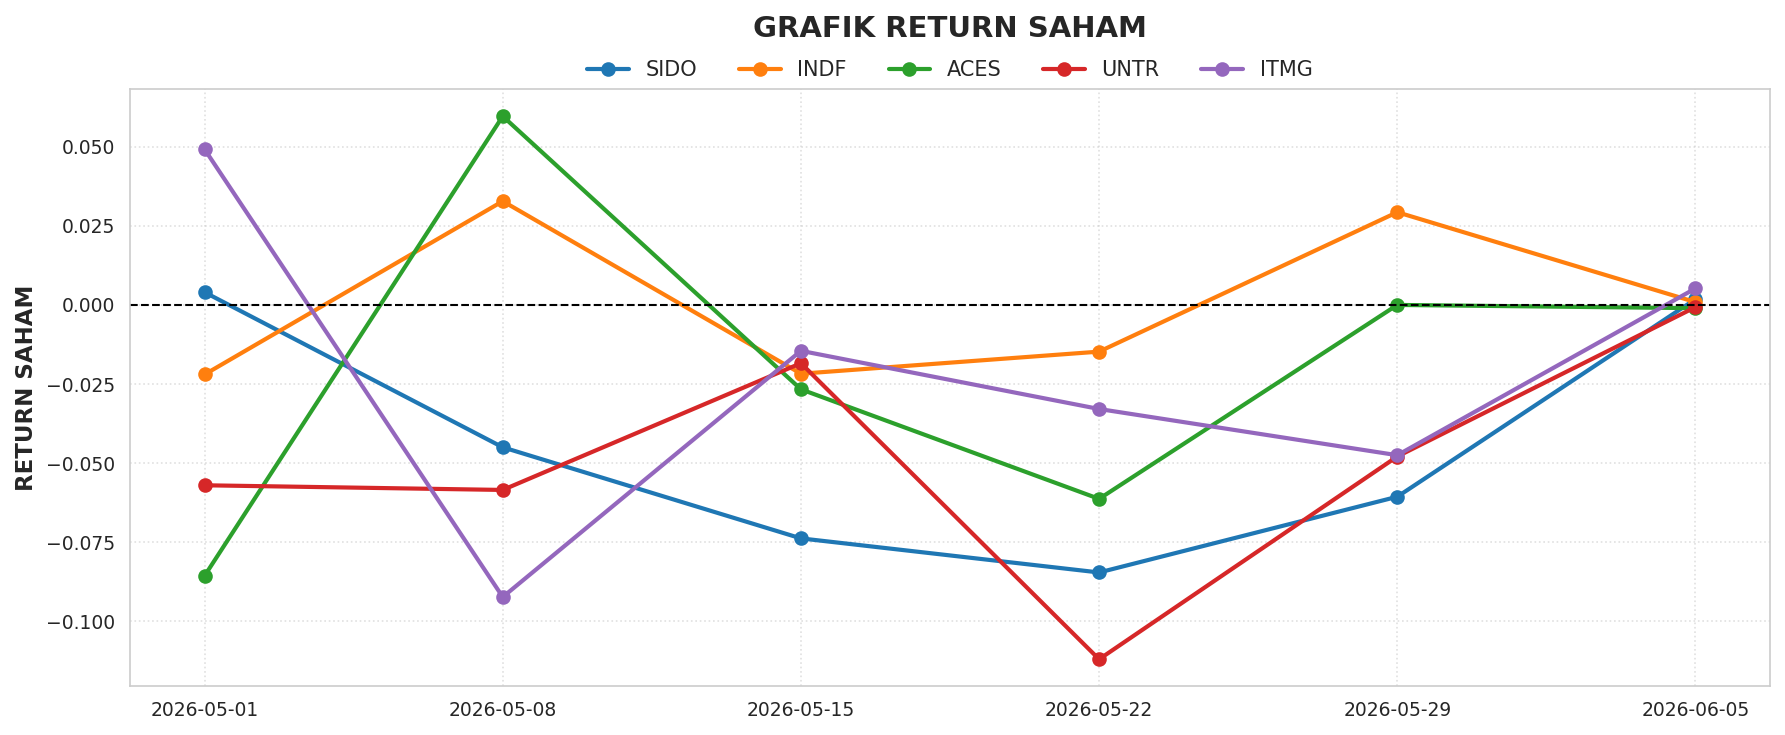

In [55]:
df_plot = df_tabel_laporan.copy()
df_plot.index = pd.to_datetime(df_plot.index, format='%d-%m-%Y')

plt.figure(figsize=(12, 5), dpi=150)
for saham in df_plot.columns:
    plt.plot(
        df_plot.index.strftime('%Y-%m-%d'),
        df_plot[saham],
        marker='o',
        linewidth=2,
        markersize=6,
        label=saham
    )
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title("GRAFIK RETURN SAHAM", fontsize=14, fontweight='bold', pad=25)
plt.ylabel("RETURN SAHAM", fontsize=11, fontweight='bold')
plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.08),
    ncol=len(df_plot.columns),
    frameon=False,
    fontsize=10
)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=0, fontsize=9)
plt.yticks(fontsize=9)

plt.tight_layout()
plt.show()

# D. BL ORIGINAL
𝝨: risk_models.CovarianceShrinkage(harga_terpilih).ledoit_wolf()
δ: black_litterman.market_implied_risk_aversion(harga_IHSG)
q: absolute views
Ω: omega="idzorek"

## return_bl

In [56]:
# Tentukan 5 saham terpilih untuk analisis Black-Litterman
nama_bl = ["SIDO", "INDF", "ACES", "UNTR", "ITMG"]
assets = nama_bl.copy()

# Filter return logaritma khusus 5 saham BL
return_bl = return_saham[assets].dropna().copy()

print("Daftar Saham BL:", assets)
print("Ukuran Data Return BL:", return_bl.shape)

Daftar Saham BL: ['SIDO', 'INDF', 'ACES', 'UNTR', 'ITMG']
Ukuran Data Return BL: (538, 5)


## λ τ rf

In [57]:
delta_BL = 2.5       # Parameter Risk Aversion (δ)
tau_BL = 0.05        # Tuning scalar prior uncertainty (τ)

# Risk-free rate tahunan (misal: BI-Rate / SBI 4.925%)
rf_annual = 0.04925
rf_weekly = np.log(1 + rf_annual) / 52  # Konversi ke log-return mingguan

print(f"Risk Aversion (δ) : {delta_BL}")
print(f"Tau (τ)           : {tau_BL}")
print(f"Rf Mingguan       : {rf_weekly:.6f}")

Risk Aversion (δ) : 2.5
Tau (τ)           : 0.05
Rf Mingguan       : 0.000925


## cov_norm

In [58]:
cov_shringkage = risk_models.CovarianceShrinkage(
   return_bl,
    returns_data=True,
    frequency=1  # Karena data sudah mingguan
).ledoit_wolf()

cov_norm = pd.DataFrame(cov_shringkage, index=assets, columns=assets)

print("\n--- Kovarians Ledoit-Wolf ---")
display(cov_norm.round(8))


--- Kovarians Ledoit-Wolf ---


,SIDO,INDF,ACES,UNTR,ITMG
SIDO,0.001471,0.000237,0.000346,0.000205,0.000184
INDF,0.000237,0.001201,0.000292,0.000189,0.000093
ACES,0.000346,0.000292,0.002604,0.000189,0.000181
UNTR,0.000205,0.000189,0.000189,0.002090,0.001080
ITMG,0.000184,0.000093,0.000181,0.001080,0.003159


## cek kovarians

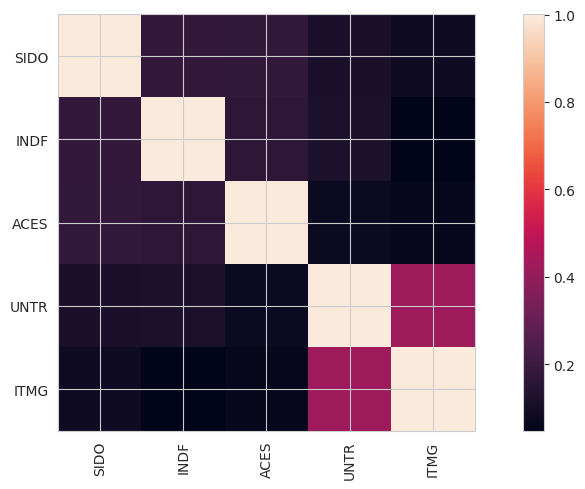

In [59]:
plotting.plot_covariance(cov_norm, plot_correlation=True);

## Market Cap

In [60]:
nama_bl = ["SIDO", "INDF", "ACES", "UNTR", "ITMG"]
market_cap = {}
# Iterate over nama_bl to ensure market caps are fetched for all relevant sahams
for saham in nama_bl:
    ticker = saham + ".JK"
    try:
        info = yf.Ticker(ticker).info
        shares = info.get("sharesOutstanding")
        price = harga_saham_clean[saham].iloc[-1]

        if shares is not None:
            market_cap[saham] = shares * price
        else:
            print(f"{saham} : Shares Outstanding tidak tersedia")
    except Exception as e:
        print(saham, e)

market_cap = pd.Series(
    market_cap,
    name="Market_Cap"
)

market_cap = market_cap.reindex(nama_bl)

print("Market Capitalization:")
display(market_cap)

# Cek
assert len(market_cap) == 5
assert market_cap.index.tolist() == nama_bl
assert market_cap.notna().all()

print("Total Market Cap:", market_cap.sum())

Market Capitalization:


,Market_Cap
SIDO,1.130312e+13
INDF,5.824890e+13
ACES,5.436824e+12
UNTR,7.875478e+13
ITMG,2.463927e+13


Total Market Cap: 178382896488978.06


## Prior : market cap

In [61]:
market_prior = (
    black_litterman
    .market_implied_prior_returns(
        market_caps=market_cap,
        risk_aversion=delta_BL,
        cov_matrix=cov_norm,
        risk_free_rate=rf_weekly
    )
)

market_prior = pd.Series(
    market_prior,
    index=assets,
    name="Market_Prior"
)

print("\nMarket Implied Prior Return (Π):")

display(
    market_prior.to_frame().round(6)
)


Market Implied Prior Return (Π):


,Market_Prior
SIDO,0.001667
INDF,0.002205
ACES,0.001687
UNTR,0.003806
ITMG,0.003327


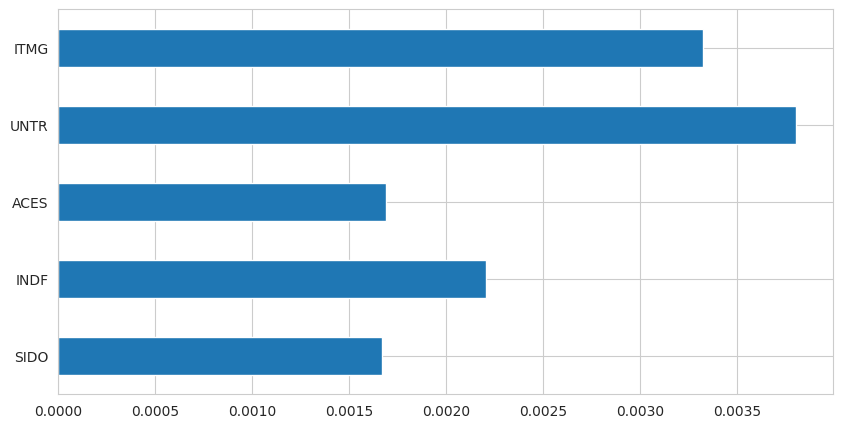

In [62]:
market_prior.plot.barh(figsize=(10,5));

## Absolute Views

In [65]:
# Absolute Views
df_pred_view = df_final_pred[df_final_pred["Pred_XGB"] > 0]

viewdict = df_pred_view.set_index("Saham")["Pred_XGB"].reindex(assets).astype(float)
viewdict.name = "View_XGB"
print("Matriks Views (q):")
display(viewdict.to_frame().round(6))

Matriks Views (q):


,View_XGB
Saham,
SIDO,0.001812
INDF,0.000884
ACES,NaN
UNTR,NaN
ITMG,0.005229


Matriks P dan Q

In [66]:
# Vektor Q (Absolute views)
active_views = viewdict.dropna()
Q = active_views.values

P = np.zeros((len(active_views), len(assets)))
for i, saham in enumerate(active_views.index):
    idx_asset = assets.index(saham)
    P[i, idx_asset] = 1

print(f"Jumlah Total Assets: {len(assets)}")
print(f"Jumlah Views Aktif (Positif): {len(Q)}\n")

# Dataframe Matriks P
df_P = pd.DataFrame(P, columns=assets, index=active_views.index)
print("Matriks Picking (P):")
display(df_P)

print("\nVektor Views (Q):")
print(Q)

Jumlah Total Assets: 5
Jumlah Views Aktif (Positif): 3

Matriks Picking (P):


,SIDO,INDF,ACES,UNTR,ITMG
Saham,,,,,
SIDO,1.0,0.0,0.0,0.0,0.0
INDF,0.0,1.0,0.0,0.0,0.0
ITMG,0.0,0.0,0.0,0.0,1.0



Vektor Views (Q):
[0.0018122  0.00088446 0.00522884]


## Confidence

In [67]:
rmse_xgb = df_test_eval.set_index("saham")["Test_RMSE"].reindex(nama_bl).astype(float)
rmse_series = rmse_xgb.reindex(assets).astype(float)
mse_series = rmse_series ** 2

# --- PERHITUNGAN CONFIDENCE IDZOREK ---
view_abs = viewdict.abs()

# Rumus Confidence: C_i = |Q_i| / (|Q_i| + RMSE_i)
confidence = view_abs / (view_abs + rmse_series)
confidence.name = "Confidence"

tabel_views = pd.concat([
    viewdict.rename("View_Q"),
    mse_series.rename("MSE"),
    rmse_series.rename("RMSE"),
    confidence
], axis=1)
tabel_views = tabel_views.dropna(subset=["View_Q"])

print("\n--- Summary Views & Confidence Idzorek ---")
display(tabel_views.round(6))



--- Summary Views & Confidence Idzorek ---


,View_Q,MSE,RMSE,Confidence
SIDO,0.001812,0.001097,0.033119,0.051880
INDF,0.000884,0.000945,0.030734,0.027973
ITMG,0.005229,0.001072,0.032738,0.137720


## Expected Return BL NORMAL

In [79]:
views_clean = viewdict.dropna()         # Berisi 3 saham positif
confidence_clean = confidence.dropna()  # Berisi 3 confidence saham positif

In [80]:
# BLACK-LITTERMAN NORMAL
bl_normal = BlackLittermanModel(
    cov_matrix=cov_norm,                # kovarians (5 x 5)
    pi=market_prior,                    # prior (5 x 1)
    absolute_views=views_clean,         # views bersih dari NaN (3 x 1)
    view_confidences=confidence_clean,  # confidence bersih dari NaN (3 x 1)
    omega="idzorek",                    # matriks omega otomatis berukuran 3 x 3
    tau=0.05,                           # tau
)
# EXPECTED RETURN BLACK-LITTERMAN NORMAL
mu_BL_normal = bl_normal.bl_returns()

print("Expected Return Black-Litterman Normal:")
display(mu_BL_normal.round(6))

Expected Return Black-Litterman Normal:


,0
SIDO,0.001682
INDF,0.002177
ACES,0.001695
UNTR,0.003891
ITMG,0.003587


## Matriks Ω

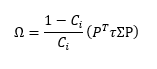

In [81]:
# MATRIKS OMEGA - IDZOREK
omega_normal = pd.DataFrame(
    bl_normal.omega,
    index=active_views.index,
    columns=active_views.index
)
print("\nMatriks Omega Idzorek:")

display(
    omega_normal.round(6)
)
print("Dimensi Ω:", omega_normal.shape)


Matriks Omega Idzorek:


Saham,SIDO,INDF,ITMG
Saham,,,
SIDO,0.001344,0.000000,0.000000
INDF,0.000000,0.002087,0.000000
ITMG,0.000000,0.000000,0.000989


Dimensi Ω: (3, 3)


In [82]:
#  P τΣ P'
P = bl_normal.P                          # matriks P (3x5)
tau_covnorm = 0.05 * cov_norm.values     # tau * Sigma (3x3)
omega_covnorm = P @ tau_covnorm @ P.T    # P * (tau * Sigma) * P^T

df_covnorm = pd.DataFrame(
    omega_covnorm,
    index=active_views.index,
    columns=active_views.index
)
print("Hasil Rumus P τΣ P':")
display(df_covnorm.round(6))

# Confidence
confidence_active = confidence_clean

# (1-Confidence)/Confidence * (P τΣ P')
omega_norm = (1 - confidence_active.values) / confidence_active.values
omega_manual_diag = np.diag(omega_covnorm) * omega_norm
omega_manual = np.diag(omega_manual_diag)

df_omega_manual = pd.DataFrame(
    omega_manual,
    index=active_views.index,
    columns=active_views.index
)
print("\nHasil Matriks Omega Manual :")
display(df_omega_manual.round(6))


Hasil Rumus P τΣ P':


Saham,SIDO,INDF,ITMG
Saham,,,
SIDO,0.000074,0.000012,0.000009
INDF,0.000012,0.000060,0.000005
ITMG,0.000009,0.000005,0.000158



Hasil Matriks Omega Manual :


Saham,SIDO,INDF,ITMG
Saham,,,
SIDO,0.001344,0.000000,0.000000
INDF,0.000000,0.002087,0.000000
ITMG,0.000000,0.000000,0.000989


In [84]:
# PERBANDINGAN PRIOR - VIEWS - POSTERIOR
hasil_BL_normal = pd.DataFrame({
    "Prior": market_prior,
    "Views_XGBoost": views_clean,
    "Posterior_BL_Normal": mu_BL_normal
})

display(
    hasil_BL_normal.round(5)
)

,Prior,Views_XGBoost,Posterior_BL_Normal
ACES,0.00169,NaN,0.00169
INDF,0.00221,0.00088,0.00218
ITMG,0.00333,0.00523,0.00359
SIDO,0.00167,0.00181,0.00168
UNTR,0.00381,NaN,0.00389


In [85]:
print(hasil_BL_normal.round(5))

        Prior  Views_XGBoost  Posterior_BL_Normal
ACES  0.00169            NaN              0.00169
INDF  0.00221        0.00088              0.00218
ITMG  0.00333        0.00523              0.00359
SIDO  0.00167        0.00181              0.00168
UNTR  0.00381            NaN              0.00389


In [83]:
P_matrix = bl_normal.P
display(P_matrix)

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

## Plot prior Views Posterior

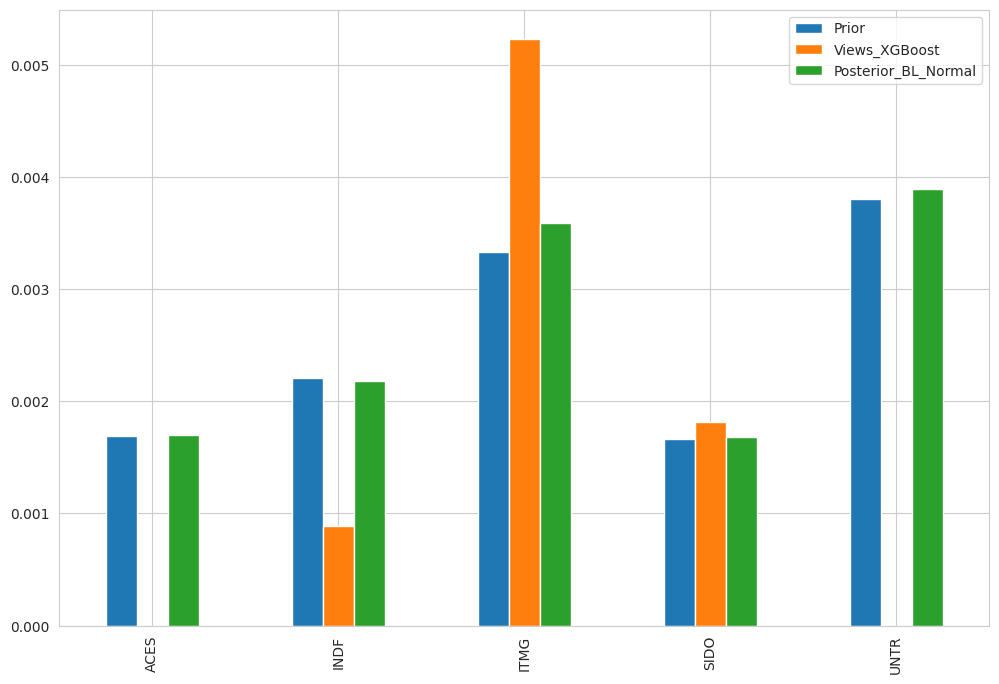

In [86]:
hasil_BL_normal.plot.bar(figsize=(12,8));

## Bobot BL Normal

In [87]:
# ============================================================
# BOBOT RETURN-IMPLIED BLACK-LITTERMAN NORMAL
# w = (δΣ)^(-1) μ_BL
# ============================================================
#delta_BL = 2.5
#weights_BL_normal = bl_normal.bl_weights(
#    risk_aversion=delta_BL
#)

#weights_BL_normal = pd.Series(
#    weights_BL_normal,
#    name="BL Normal"
#)

#print("Bobot BL Normal:")
#display(
#    weights_BL_normal.to_frame().round(5)
#)

#print(
#    "Jumlah bobot:",
#    weights_BL_normal.sum()
#)

Bobot BL Normal:


,BL Normal
SIDO,0.14258
INDF,0.32764
ACES,0.06687
UNTR,0.32376
ITMG,0.13915


Jumlah bobot: 1.0


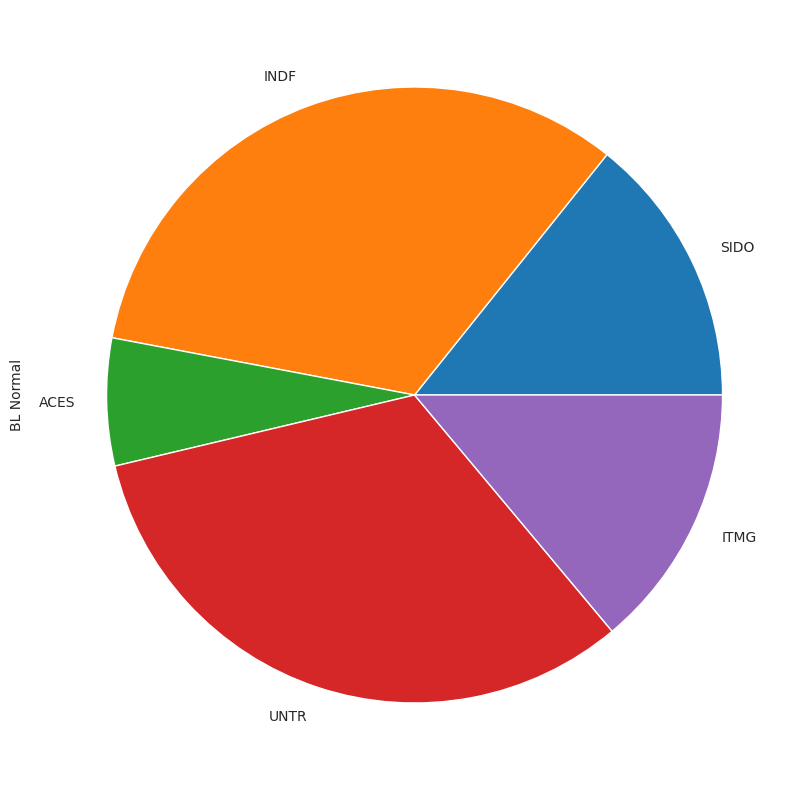

In [88]:
pd.Series(weights_BL_normal).plot.pie(figsize=(10,10));

## Perbandingan bobot SLSQP

In [126]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. Pastikan Fungsi Objektif Sudah Didefinisikan (Sama seperti Skew-Normal)
def objective_utility(w, mu, cov, delta):
    portfolio_return = np.dot(w, mu)
    portfolio_variance = np.dot(w.T, np.dot(cov, w))
    # Minimasi negative utility (setara dengan maksimasi utility)
    return -(portfolio_return - (delta / 2) * portfolio_variance)

# ============================================================
# BOBOT RETURN-IMPLIED BLACK-LITTERMAN NORMAL (METODE SLSQP)
# ============================================================

# 2. Inisialisasi Data BL Normal
mu_normal = mu_BL_normal.values    # Expected Return BL Normal (Hasil dari bl_normal.bl_returns())
cov_normal = cov_norm.values       # Matriks Kovarians BL Normal
num_assets = len(assets)
delta_BL = 2.5                     # Koefisien Risk Aversion

# 3. Kendala dan Batasan (Persis sama dengan Skew-Normal: w >= 0, sum(w) = 1)
bounds = tuple((0, 1) for _ in range(num_assets))              # w_i >= 0
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) # sum(w) = 1
initial_weights = np.array([1 / num_assets] * num_assets)      # Equal-weighted start

# 4. Optimasi Menggunakan scipy.optimize dengan Metode SLSQP
result_normal = minimize(
    objective_utility,
    initial_weights,
    args=(mu_normal, cov_normal, delta_BL),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# 5. Format Hasil Bobot ke pd.Series
weights_BL_normal = pd.Series(result_normal.x, index=assets, name="BL Normal")

# --- TAMPILKAN HASIL ---
print("Bobot BL Normal (w >= 0, sum(w) = 1 via SLSQP):")
display(
    weights_BL_normal.to_frame().round(5)
)

print(
    "Jumlah bobot:",
    round(weights_BL_normal.sum(), 5)
)

Bobot BL Normal (w >= 0, sum(w) = 1 via SLSQP):


,BL Normal
SIDO,0.11397
INDF,0.23857
ACES,0.01582
UNTR,0.38418
ITMG,0.24747


Jumlah bobot: 1.0


# E. BL SKEW NORMAL NEXT

## Teoritis vs Empiris

In [93]:
# PERBANDINGAN MOMEN EMPIRIS DAN MOMEN TEORITIS
from scipy.stats import skew, kurtosis

# 1. Momen Teoritis Skew-Normal (Mengambil kolom dan memfilter indeks berdasarkan nama_terpilih)
moment_skew = df_hasil_skewnorm[["Mean_Teoritis", "Variance_Teoritis", "Std_Teoritis", "Skewness_Gamma1", "Excess_Kurtosis_Gamma2"]].reindex(nama_terpilih).copy()

# Interpretasi Momen (Otomatis hanya berjalan untuk 5 saham terpilih)
moment_skew["Interpretasi_Skewness"] = moment_skew["Skewness_Gamma1"].apply(lambda x: "Right Skew" if x > 0 else "Left Skew" if x < 0 else "Simetris")
moment_skew["Interpretasi_Kurtosis"] = moment_skew["Excess_Kurtosis_Gamma2"].apply(lambda x: "Leptokurtik (Heavy Tail)" if x > 0 else "Mesokurtik (Normal Tail)" if x == 0 else "Platikurtik (Light Tail)")

# Mengatur nama indeks
moment_skew.index.name = "Saham"

print("\nMOMEN TEORITIS DISTRIBUSI SKEW-NORMAL (5 SAHAM TERPILIH)")
display(moment_skew.round(5))


MOMEN TEORITIS DISTRIBUSI SKEW-NORMAL (5 SAHAM TERPILIH)


,Mean_Teoritis,Variance_Teoritis,Std_Teoritis,Skewness_Gamma1,Excess_Kurtosis_Gamma2,Interpretasi_Skewness,Interpretasi_Kurtosis
Saham,,,,,,,
SIDO,0.00161,0.00142,0.03767,-0.06326,0.02205,Left Skew,Leptokurtik (Heavy Tail)
INDF,0.00094,0.00113,0.03359,-0.10970,0.04593,Left Skew,Leptokurtik (Heavy Tail)
ACES,-0.00085,0.00264,0.05138,0.07569,0.02800,Right Skew,Leptokurtik (Heavy Tail)
UNTR,0.00196,0.00208,0.04566,-0.13484,0.06048,Left Skew,Leptokurtik (Heavy Tail)
ITMG,0.00511,0.00323,0.05685,0.10223,0.04181,Right Skew,Leptokurtik (Heavy Tail)


In [94]:
# 2. Statistik Empiris Data Return
statistik_empiris = {}
for saham in nama_terpilih:
    data = return_terpilih[saham].dropna()
    statistik_empiris[saham] = {
        "Mean_Data": data.mean(),
        "Variance_Data": data.var(),
        "Std_Data": data.std(),
        "Skewness_Data": skew(data, bias=False),
        "Kurtosis_Data": kurtosis(data, fisher=True, bias=False)
    }

statistik_empiris = pd.DataFrame(statistik_empiris).T
statistik_empiris.index.name = "Saham"

print("\nSTATISTIK EMPIRIS DATA RETURN")
display(statistik_empiris.round(5))


STATISTIK EMPIRIS DATA RETURN


,Mean_Data,Variance_Data,Std_Data,Skewness_Data,Kurtosis_Data
Saham,,,,,
SIDO,0.00171,0.00143,0.03776,-0.05608,7.74297
INDF,0.00104,0.00113,0.03368,-0.18405,3.75465
ACES,-0.00089,0.00265,0.05145,0.02729,1.42266
UNTR,0.00203,0.00209,0.04575,-0.14158,1.21263
ITMG,0.00501,0.00324,0.05696,0.06112,2.28371


## BL SN

In [95]:
# PARAMETERISASI BLACK-LITTERMAN SKEW-NORMAL
assets = nama_terpilih

# 1. Matriks Standar Deviasi (σ)
std_saham = np.sqrt(np.diag(cov_norm.values))
D_sigma = pd.DataFrame(np.diag(std_saham), index=assets, columns=assets)

print("=" * 70); print("MATRIKS STANDAR DEVIASI (σ)"); print("=" * 70)
display(D_sigma.round(5))

# 2. Matriks Korelasi (Σ̄)
D_inv = np.linalg.inv(D_sigma.values)
Sigma_bar_values = D_inv @ cov_norm.values @ D_inv
Sigma_bar = pd.DataFrame(Sigma_bar_values, index=assets, columns=assets)

print("=" * 70); print("MATRIKS KORELASI (Σ̄)"); print("=" * 70)
display(Sigma_bar.round(5))

MATRIKS STANDAR DEVIASI (σ)


,SIDO,INDF,ACES,UNTR,ITMG
SIDO,0.03835,0.00000,0.00000,0.00000,0.0000
INDF,0.00000,0.03465,0.00000,0.00000,0.0000
ACES,0.00000,0.00000,0.05103,0.00000,0.0000
UNTR,0.00000,0.00000,0.00000,0.04572,0.0000
ITMG,0.00000,0.00000,0.00000,0.00000,0.0562


MATRIKS KORELASI (Σ̄)


,SIDO,INDF,ACES,UNTR,ITMG
SIDO,1.00000,0.17811,0.17704,0.11683,0.08546
INDF,0.17811,1.00000,0.16491,0.11920,0.04773
ACES,0.17704,0.16491,1.00000,0.08104,0.06316
UNTR,0.11683,0.11920,0.08104,1.00000,0.42042
ITMG,0.08546,0.04773,0.06316,0.42042,1.00000


## Parameter δ skew normal
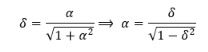

In [96]:
# α = δ / sqrt(1 - δ²)
alpha = pd.Series(
    df_hasil_skewnorm.loc[:, "Shape (α)"],
    index=assets,
    name="Shape (α)"
)
print("Parameter shape alpha:")
display(
    alpha.to_frame().round(5)
)

# δ = α / sqrt(1 + α²)
delta_skew = (
    alpha
    /
    np.sqrt(1 + alpha**2)
)
delta_skew.name = "Delta_MLE"

print("Parameter delta skew-normal:")
display(
    delta_skew.to_frame().round(5)
)

Parameter shape alpha:


,Shape (α)
SIDO,-0.72203
INDF,-0.90635
ACES,0.77590
UNTR,-0.99300
ITMG,0.87930


Parameter delta skew-normal:


,Delta_MLE
SIDO,-0.58539
INDF,-0.67156
ACES,0.61301
UNTR,-0.70462
ITMG,0.66033


## Alpha Tilde
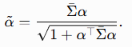

In [97]:
# α̃ = Σ̄α / sqrt(1 + α'Σ̄α)
alpha_vector = alpha.values.reshape(-1, 1)
quadratic_alpha = (alpha_vector.T @ Sigma_bar.values @ alpha_vector)[0, 0]
denominator_alpha_tilde = np.sqrt(1 + quadratic_alpha)

alpha_tilde_values = (Sigma_bar.values @ alpha_vector) / denominator_alpha_tilde
alpha_tilde = pd.Series(alpha_tilde_values.flatten(), index=assets, name="Alpha_Tilde")

print("Parameter alpha_tilde:")
display(
    alpha_tilde.to_frame().round(5)
)

Parameter alpha_tilde:


,Alpha_Tilde
SIDO,-0.39690
INDF,-0.49596
ACES,0.23889
UNTR,-0.37968
ITMG,0.20469


## Matriks Σ_x
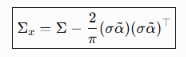

In [98]:
# MATRIKS KOVARIANS TERKOREKSI (Σ_x)
# σ α_tilde
sigma_alpha_tilde = (
    D_sigma.values
    @ alpha_tilde.values.reshape(-1, 1)
)
sigma_alpha_tilde = pd.Series(
    sigma_alpha_tilde.flatten(),
    index=assets,
    name="Sigma_Alpha_Tilde"
)
print("sigma alpha_tilde:")
display(
    sigma_alpha_tilde.to_frame().round(5)
)

sigma alpha_tilde:


,Sigma_Alpha_Tilde
SIDO,-0.01522
INDF,-0.01719
ACES,0.01219
UNTR,-0.01736
ITMG,0.01150


In [99]:
# Koreksi Matriks Kovarians
# Rumus: Σ_x = Σ - (2/π) * (σ * α̃) * (σ * α̃)'
v = (
    sigma_alpha_tilde.values
    .reshape(-1, 1)
)

cov_x_values = (
    cov_norm.values
    -
    (2 / np.pi)
    *
    (v @ v.T)
)

cov_x = pd.DataFrame(
    cov_x_values,
    index=assets,
    columns=assets
)

# Memastikan simetris akibat numerical precision
cov_x = (
    cov_x + cov_x.T
) / 2

print("Matriks Kovarians Skew Normal (cov_x):")
display(
    cov_x.round(8)
)

print("Dimensi cov_x:", cov_x.shape)

Matriks Kovarians Skew Normal (cov_x):


,SIDO,INDF,ACES,UNTR,ITMG
SIDO,0.001324,0.000070,0.000465,0.000037,0.000296
INDF,0.000070,0.001013,0.000425,-0.000001,0.000219
ACES,0.000465,0.000425,0.002509,0.000324,0.000092
UNTR,0.000037,-0.000001,0.000324,0.001899,0.001208
ITMG,0.000296,0.000219,0.000092,0.001208,0.003075


Dimensi cov_x: (5, 5)


## Prior, Q, Confidence

In [103]:
assets = nama_terpilih.copy()
N = len(assets)

# 1. Prior market-implied
Pi = market_prior.copy()
Pi = Pi.reindex(assets)
Pi.name = "Prior"

# 2. Vektor Views
# views_clean adalah Series yang indeksnya sudah nama saham, cukup reindex langsung
Q = views_clean.reindex(assets)
Q.name = "Views"

# 3. Confidence berdasarkan MSE XGBoost (Diambil dari df_test_eval)
# Test_RMSE dikuadratkan untuk menghasilkan MSE
mse_saham = df_test_eval.set_index("saham")["Test_RMSE"].reindex(assets) ** 2
mse_saham.name = "MSE"

# RMSE per saham
rmse_saham = np.sqrt(mse_saham)
rmse_saham.name = "RMSE"

# Tingkat Keyakinan (Confidence) Idzorek
confidence = Q.abs() / (Q.abs() + rmse_saham)
confidence = confidence.clip(0, 1)
confidence.name = "Confidence"

# Input BL
hasil_input_BL = pd.concat(
    [
        Pi,
        Q,
        mse_saham,
        rmse_saham,
        confidence
    ],
    axis=1
)
print("Input Black-Litterman:")
display(
    hasil_input_BL.round(8)
)

Input Black-Litterman:


,Prior,Views,MSE,RMSE,Confidence
SIDO,0.001667,0.001812,0.001097,0.033119,0.051880
INDF,0.002205,0.000884,0.000945,0.030734,0.027973
ACES,0.001687,NaN,0.002227,0.047187,NaN
UNTR,0.003806,NaN,0.001709,0.041339,NaN
ITMG,0.003327,0.005229,0.001072,0.032738,0.137720


In [ ]:
print(cov_x)

In [ ]:
print(cov_norm)

## Matriks Ω

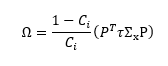

In [105]:
#  P ́ ̂Γ̑_x P'
P = bl_normal.P                          # matriks P (3x5)
tau_covskew = 0.05 * cov_x.values        # tau * Sigma.x (5x5)
omega_covskew = P @ tau_covskew @ P.T    # P * (tau * Sigma.x) * P^T (3x3)

# PERBAIKAN: Gunakan active_views.index (3 elemen) bukan viewdict.keys() (5 elemen)
df_covskew = pd.DataFrame(
    omega_covskew,
    index=active_views.index,
    columns=active_views.index
)
print("Hasil Rumus P ́Γ P':")
display(df_covskew.round(6))

# Confidence untuk active views
confidence_active = confidence_clean

# (1-Confidence)/Confidence * (P ́ ̂Γ_x P')
omega_skew_factor = (1 - confidence_active.values) / confidence_active.values
omega_skew_diag = np.diag(omega_covskew) * omega_skew_factor
omega_skew = np.diag(omega_skew_diag)

# PERBAIKAN: Gunakan active_views.index untuk DataFrame Omega Skew
df_omega_skew = pd.DataFrame(
    omega_skew,
    index=active_views.index,
    columns=active_views.index
)
print("\nHasil Matriks Omega Manual :")
display(df_omega_skew.round(6))

Hasil Rumus P ́Γ P':


Saham,SIDO,INDF,ITMG
Saham,,,
SIDO,0.000066,0.000004,0.000015
INDF,0.000004,0.000051,0.000011
ITMG,0.000015,0.000011,0.000154



Hasil Matriks Omega Manual :


Saham,SIDO,INDF,ITMG
Saham,,,
SIDO,0.001209,0.00000,0.000000
INDF,0.000000,0.00176,0.000000
ITMG,0.000000,0.00000,0.000963


In [106]:
C = np.diag(
    confidence.reindex(assets).values
)
print("Matriks C")
display(pd.DataFrame(C, index=assets, columns=assets))

Matriks C


,SIDO,INDF,ACES,UNTR,ITMG
SIDO,0.05188,0.000000,0.0,0.0,0.00000
INDF,0.00000,0.027973,0.0,0.0,0.00000
ACES,0.00000,0.000000,NaN,0.0,0.00000
UNTR,0.00000,0.000000,0.0,NaN,0.00000
ITMG,0.00000,0.000000,0.0,0.0,0.13772


## Matriks P

In [108]:
P_matrix = bl_normal.P
display(P_matrix)

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

## Komponen BL Skew

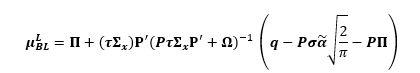

In [111]:
import numpy as np
import pandas as pd

# Prior market-implied (5x1)
Pi_vec = Pi.values if isinstance(Pi, (pd.Series, pd.DataFrame)) else Pi

# Gunakan P_matrix (3x5) yang merepresentasikan views aktif, bukan P_mat (5x5)
P_mat = P_matrix

# Ambil Q_vec hanya untuk views aktif (3x1)
Q_vec = views_clean.values

# Matriks Omega Skew (3x3)
omega_skew = np.diag(omega_skew_diag)

# ̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄
# ̄̄̄ KOPOMNEN FORMULA BL SKEW-NORMAL ̄̄̄
# ̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄
# ̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄̄

tau = 0.05
tau_covskew = tau * cov_x.values

# # (tau_covskew)P^T (5x3)
covskew_P = tau_covskew @ P_mat.T

# (P(tau*Sigma_x)P^T + Omega)^-1 (3x3)
middle_term = np.linalg.inv(P_mat @ tau_covskew @ P_mat.T + omega_skew)

# Hitung b = sigma * alpha_tilde * sqrt(2/pi) (5x1)
b_values = std_saham * alpha_tilde.values * np.sqrt(2 / np.pi)
b = pd.Series(b_values, index=assets, name="b")
print("Komponen parameter b:")
display(b.to_frame().round(5))

# Q - P(b) - P*Pi (3x1)
hit_skew = Q_vec - (P_mat @ b.values) - (P_mat @ Pi_vec)
hit_skew_df = pd.DataFrame(hit_skew, index=views_clean.index, columns=["Value"])
print("\nKomponen Views Skew Normal [Q - P(b) - P*Pi]:")
display(hit_skew_df.round(5))

Komponen parameter b:


,b
SIDO,-0.01215
INDF,-0.01371
ACES,0.00973
UNTR,-0.01385
ITMG,0.00918



Komponen Views Skew Normal [Q - P(b) - P*Pi]:


,Value
Saham,
SIDO,0.01229
INDF,0.01239
ITMG,-0.00728


## Posterior BL Skew Normal
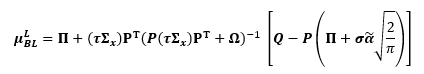

In [112]:
# Posterior Black-Litterman Skew Normal
# Π + (τΣ_x)Pᵀ (P(τΣ_x)Pᵀ+ Ω)(^-1) [Q - P(b) - PΠ]
mu_BL_SN_values = Pi_vec + (covskew_P @ middle_term ) @ hit_skew

mu_BL_SN = pd.Series(
    mu_BL_SN_values.flatten(), index=assets, name="μ_BL_SN"
)
display(mu_BL_SN.round(5))

,μ_BL_SN
SIDO,0.00223
INDF,0.00251
ACES,0.00203
UNTR,0.00342
ITMG,0.00251


## Plot N vs SN

In [113]:
hasil_final = pd.DataFrame({
    "Prior": Pi,
    "Views_XGBoost": Q,
    "Posterior_BL_Normal": mu_BL_normal,
    "Posterior_BL_Skew_Normal": mu_BL_SN
})

display(
    hasil_final.round(5)
)

,Prior,Views_XGBoost,Posterior_BL_Normal,Posterior_BL_Skew_Normal
SIDO,0.00167,0.00181,0.00168,0.00223
INDF,0.00221,0.00088,0.00218,0.00251
ACES,0.00169,NaN,0.00169,0.00203
UNTR,0.00381,NaN,0.00389,0.00342
ITMG,0.00333,0.00523,0.00359,0.00251


In [ ]:
print(hasil_final.round(5))

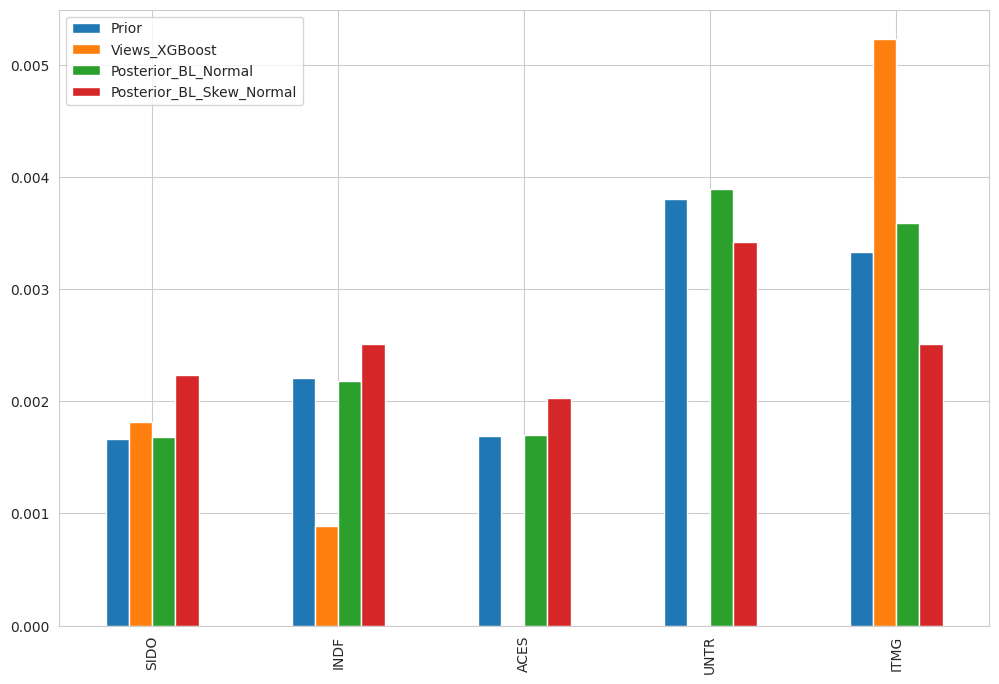

In [114]:
hasil_final.plot.bar(figsize=(12,8));

## Bobot N vs SN

In [115]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# 1. Definisi Parameter dan Fungsi Objektif (Maksimasi Utility: w^T * mu - (delta/2) * w^T * Sigma * w)
def objective_utility(w, mu, cov, delta):
    portfolio_return = np.dot(w, mu)
    portfolio_variance = np.dot(w.T, np.dot(cov, w))
    # Minimasi negative utility (setara dengan maksimasi utility)
    return -(portfolio_return - (delta / 2) * portfolio_variance)

# 2. Inisialisasi Data
mu_sn = mu_BL_SN.values          # Expected Return BL Skew Normal
cov_sn = cov_x.values            # Matriks Kovarians BL Skew Normal
num_assets = len(assets)
delta_BL = 2.5                     # Koefisien Risk Aversion

# 3. Kendala dan Batasan (Constraints & Bounds)
bounds = tuple((0, 1) for _ in range(num_assets))              # w_i >= 0
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1}) # sum(w) = 1
initial_weights = np.array([1 / num_assets] * num_assets)      # Equal-weighted start

# 4. Optimasi Menggunakan scipy.optimize
result = minimize(
    objective_utility,
    initial_weights,
    args=(mu_sn, cov_sn, delta_BL),
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

# 5. Format Hasil Bobot ke pd.Series
weights_BL_SN = pd.Series(result.x, index=assets, name="BL Skew Normal")

print("Bobot Portofolio BL Skew Normal (w >= 0, sum(w) = 1):")
print(weights_BL_SN.round(4))

Bobot Portofolio BL Skew Normal (w >= 0, sum(w) = 1):
SIDO    0.2474
INDF    0.3668
ACES    0.0108
UNTR    0.3751
ITMG    0.0000
Name: BL Skew Normal, dtype: float64


## visualisasi Bobot

In [127]:
# 1. Menggabungkan bobot BL Normal dan BL Skew Normal
df_weights = pd.DataFrame({
    "BL Normal": weights_BL_normal,
    "BL Skew Normal": weights_BL_SN
})

# 2. Menambahkan baris Total untuk verifikasi sum(w) = 1
df_weights.loc["TOTAL"] = df_weights.sum()

# 3. Menampilkan hasil dengan format persentase
print("=== PERBANDINGAN BOBOT PORTOFOLIO ===")
display(df_weights.round(4))

=== PERBANDINGAN BOBOT PORTOFOLIO ===


,BL Normal,BL Skew Normal
SIDO,0.1140,0.2474
INDF,0.2386,0.3668
ACES,0.0158,0.0108
UNTR,0.3842,0.3751
ITMG,0.2475,0.0000
TOTAL,1.0000,1.0000


<Axes: title={'center': 'Perbandingan Bobot Portofolio: BL Normal vs BL Skew Normal'}>

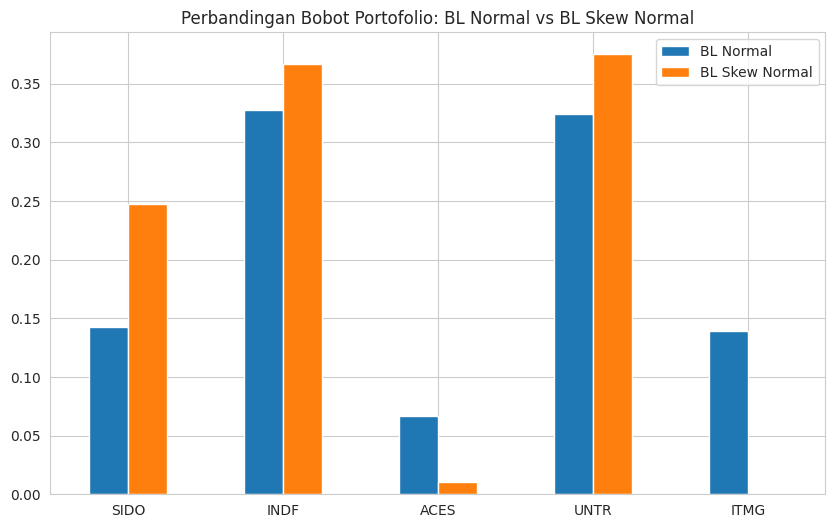

In [117]:
# 4. Plot Visualisasi Perbandingan Bobot
df_weights.drop("TOTAL").plot(
    kind="bar",
    figsize=(10, 6),
    rot=0,
    title="Perbandingan Bobot Portofolio: BL Normal vs BL Skew Normal"
)

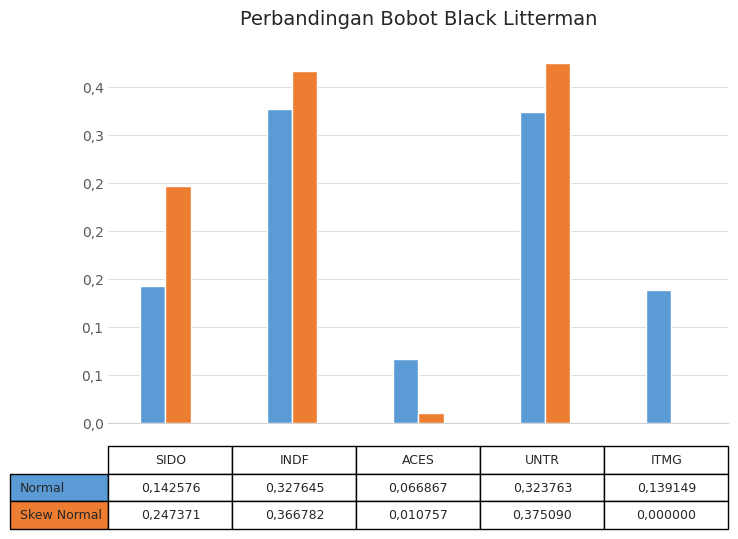

In [118]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Siapkan data tanpa baris TOTAL
df_plot = df_weights.drop("TOTAL", errors="ignore").copy()

# Rename kolom agar sesuai legenda gambar
df_plot.columns = ["Normal", "Skew Normal"]

# 2. Buat figure dan subplots
fig, ax = plt.subplots(figsize=(8, 6))

# Plot bar diagram
colors = ["#5B9BD5", "#ED7D31"]  # Warna biru & oranye khas Excel
df_plot.plot(
    kind="bar",
    ax=ax,
    color=colors,
    width=0.4,
    legend=False,  # Legenda disatukan ke dalam tabel di bawah
    zorder=3
)

# 3. Styling Grafik (Meniru gaya Excel)
ax.set_title("Perbandingan Bobot Black Litterman", fontsize=14, pad=15)
ax.set_xlabel("")
ax.set_ylabel("")

# Grid horizontal saja
ax.yaxis.grid(True, linestyle="-", color="#D3D3D3", alpha=0.7, zorder=0)
ax.xaxis.grid(False)

# Hilangkan garis spine/border atas, kanan, dan kiri
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#D3D3D3")

# Sumbu Y dengan tanda koma (gaya penulisan Indonesia)
ticks_y = ax.get_yticks()
ax.set_yticklabels([f"{y:.1f}".replace('.', ',') for y in ticks_y], color="#595959")
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", bottom=False, labelbottom=False) # Sembunyikan label X default karena diganti tabel

# 4. Membuat Tabel Data di Bawah Grafik
# Format angka menggunakan 6 desimal dan koma sebagai pemisah desimal
cell_text = []
for col in df_plot.columns:
    cell_text.append([f"{val:.6f}".replace('.', ',') for val in df_plot[col]])

table_data = plt.table(
    cellText=cell_text,
    rowLabels=df_plot.columns,
    colLabels=df_plot.index,
    rowColours=colors,
    cellLoc="center",
    rowLoc="left",
    loc="bottom",
    bbox=[0.0, -0.28, 1.0, 0.22] # [x, y, width, height]
)

# Formatting font dan ukuran tabel
table_data.auto_set_font_size(False)
table_data.set_fontsize(9)

# Menyesuaikan jarak bawah agar tabel tidak terpotong
plt.subplots_adjust(bottom=0.25)

plt.show()

## Return Risiko Porto

In [119]:
import numpy as np
import pandas as pd

# ==============================================================================
# 1. PERHITUNGAN PORTOFOLIO BLACK-LITTERMAN NORMAL
# ==============================================================================
# Inisialisasi variabel BL Normal
w_normal = weights_BL_normal.values if isinstance(weights_BL_normal, pd.Series) else weights_BL_normal
mu_normal = mu_BL_normal.values if isinstance(mu_BL_normal, pd.Series) else mu_BL_normal
cov_normal = cov_norm.values if isinstance(cov_norm, pd.DataFrame) else cov_norm  # Matriks Kovarians BL Normal (S_bl)

# Expected Return: E(Rp) = w^T @ mu
er_bl_normal = np.dot(w_normal.T, mu_normal)

# Varians & Risiko Portofolio: sigma_p = sqrt(w^T @ Sigma @ w)
var_bl_normal = np.dot(w_normal.T, np.dot(cov_normal, w_normal))
risks_bl_normal = np.sqrt(var_bl_normal)


# ==============================================================================
# 2. PERHITUNGAN PORTOFOLIO BLACK-LITTERMAN SKEW-NORMAL
# ==============================================================================
# Inisialisasi variabel BL Skew-Normal
w_sn = weights_BL_SN.values if isinstance(weights_BL_SN, pd.Series) else weights_BL_SN
mu_sn = mu_BL_SN.values if isinstance(mu_BL_SN, pd.Series) else mu_BL_SN
cov_sn = cov_x.values if isinstance(cov_x, pd.DataFrame) else cov_x  # Matriks Kovarians BL Skew-Normal (Sigma_x)

# Expected Return: E(Rp) = w^T @ mu
er_bl_sn = np.dot(w_sn.T, mu_sn)

# Varians & Risiko Portofolio: sigma_p = sqrt(w^T @ Sigma_x @ w)
var_bl_sn = np.dot(w_sn.T, np.dot(cov_sn, w_sn))
risks_bl_sn = np.sqrt(var_bl_sn)


# ==============================================================================
# 3. PERBANDINGAN DAN TAMPILAN DATAFRAME
# ==============================================================================
hasil_evaluasi = pd.DataFrame({
    "BL Normal": [er_bl_normal, var_bl_normal, risks_bl_normal],
    "BL Skew Normal": [er_bl_sn, var_bl_sn, risks_bl_sn]
}, index=["Expected Return E(Rp)", "Varians Portofolio (sigma_p^2)", "Risiko Portofolio (sigma_p)"])

print("=== HASIL EVALUASI RETURN DAN RISIKO PORTOFOLIO ===")
display(hasil_evaluasi.round(5))

=== HASIL EVALUASI RETURN DAN RISIKO PORTOFOLIO ===


,BL Normal,BL Skew Normal
Expected Return E(Rp),0.00283,0.00278
Varians Portofolio (sigma_p^2),0.00068,0.00051
Risiko Portofolio (sigma_p),0.02600,0.02263


## Sharpe Ratio

In [ ]:
rf_weekly

In [120]:
SR_norm = er_bl_normal/risks_bl_normal
print("Sharpe Ratio Normal :", SR_norm.round(4))

SR_skew=er_bl_sn/risks_bl_sn
print("Sharpe Ratio Skew Normal :", SR_skew.round(4))

Sharpe Ratio Normal : 0.1087
Sharpe Ratio Skew Normal : 0.1227


In [121]:
SR_norm = (er_bl_normal-rf_weekly)/risks_bl_normal
print("Sharpe Ratio Normal :", SR_norm.round(4))

SR_skew=(er_bl_sn-rf_weekly)/risks_bl_sn
print("Sharpe Ratio Skew Normal :", SR_skew.round(4))

Sharpe Ratio Normal : 0.0731
Sharpe Ratio Skew Normal : 0.0819


## matriks Σ & matriks Ω

In [122]:
print(cov_norm)

          SIDO      INDF      ACES      UNTR      ITMG
SIDO  0.001471  0.000237  0.000346  0.000205  0.000184
INDF  0.000237  0.001201  0.000292  0.000189  0.000093
ACES  0.000346  0.000292  0.002604  0.000189  0.000181
UNTR  0.000205  0.000189  0.000189  0.002090  0.001080
ITMG  0.000184  0.000093  0.000181  0.001080  0.003159


In [123]:
print(cov_x)

          SIDO      INDF      ACES      UNTR      ITMG
SIDO  0.001324  0.000070  0.000465  0.000037  0.000296
INDF  0.000070  0.001013  0.000425 -0.000001  0.000219
ACES  0.000465  0.000425  0.002509  0.000324  0.000092
UNTR  0.000037 -0.000001  0.000324  0.001899  0.001207
ITMG  0.000296  0.000219  0.000092  0.001207  0.003075


In [124]:
print(omega_manual)

[[0.00134419 0.         0.        ]
 [0.         0.00208658 0.        ]
 [0.         0.         0.0009889 ]]


In [125]:
print(omega_skew)

[[0.00120939 0.         0.        ]
 [0.         0.00175983 0.        ]
 [0.         0.         0.00096253]]
